In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

plt.style.use('ggplot')

In [2]:
def pbc(index,SIZE):
    if index+1 > SIZE-1:
        return 0
    elif index-1 < 0:
        return SIZE-1
    else:
        return index

def energy_1D(red_1D, i, H, N, J=0):

    if J == 1: # Caso ferromagnético: J = 1
        return -1 * red_1D[i] * (red_1D[pbc(i-1,N)] + red_1D[pbc(i+1,N)]) - red_1D[i] * H

    elif J == 0: # Caso sin interacción: J = 0
        return -red_1D[i] * H

    else:
        print("ERROR")
        print("No se ha definido el caso J!=0 o J!=1")


def energy_2D(red_2D, i, j, H, N,J=0):
    if J == 1:
        return -1 * red_2D[i,j] * (red_2D[pbc(i-1,N),j] + red_2D[pbc(i+1,N),j] +
                                   red_2D[i,pbc(j-1,N)] + red_2D[i,pbc(j+1,N)] ) - red_2D[i,j] * H
    elif J == 0:
        return -red_2D[i,j] * H
    else:
        print("ERROR")
        print("No se ha definido el caso J!=0 o J!=1")


def energy_3D(red_3D, i, j, k, H, N, J=0):
    if J == 1:
        return -1 * red_3D[i,j,k] * ( red_3D[pbc(i-1,N), pbc(j-1,N), pbc(k,N)] +
                                      red_3D[pbc(i-1,N), pbc(j-1,N), pbc(k,N)] +
                                      red_3D[pbc(i-1,N), pbc(j+1,N), pbc(k,N)] +
                                      red_3D[pbc(i-1,N), pbc(j+1,N), pbc(k,N)] +
                                      red_3D[pbc(i+1,N), pbc(j-1,N), pbc(k,N)] +
                                      red_3D[pbc(i+1,N), pbc(j-1,N), pbc(k,N)] +
                                      red_3D[pbc(i+1,N), pbc(j+1,N), pbc(k,N)] +
                                      red_3D[pbc(i+1,N), pbc(j+1,N), pbc(k,N)]) - red_3D[i,j,k] * H

    elif J == 0:
        return -red_3D[i,j,k] * H

    else:
        print("ERROR")
        print("No se ha definido el caso J!=0 o J!=1")

def energy_hex(red_hex, i, j, H, N, J=0):
    if J == 1:
        if i%2==0: # Fila par
            return -1 * red_hex[i,j]  * (red_hex[pbc(i-1,N),j] +
                                         red_hex[pbc(i+1,N),pbc(j-1,N)] +
                                         red_hex[pbc(i+1,N),pbc(j+1,N)] ) - red_hex[i,j] * H

        elif i%2==1: # Fila impar
             return -1 * red_hex[i,j]  * (red_hex[pbc(i+1,N),j] +
                                          red_hex[pbc(i-1,N),pbc(j-1,N)] +
                                          red_hex[pbc(i-1,N),pbc(j+1,N)] ) - red_hex[i,j] * H
    elif J == 0:
        return -red_hex[i,j] * H

    else:
        print("ERROR")
        print("No se ha definido el caso J!=0 o J!=1")

In [3]:
def grafica1(H, m1, m2, m3, T, q,z):
    # =====================
    # 1️⃣ Primera figura: m vs H
    # =====================
    plt.figure(figsize=(8, 6))
    plt.plot(H, m1, '--o', label=f'T = {T[0]}')
    plt.plot(H, m2, '--s', label=f'T = {T[1]}')
    plt.plot(H, m3, ':^', label=f'T = {T[2]}')

    plt.xlabel('H', color='black', fontsize=16)
    plt.ylabel('m', color='black', fontsize=16)
    plt.title(f'Curva m vs H, q={q}, z={z}', fontsize=18, color='black', pad=15)
    plt.legend()
    plt.grid(True)
    plt.tick_params(axis='both', labelsize=12)
    plt.tight_layout()
    plt.show()

    print("\n\n")

    # =====================
    # 2️⃣ Segunda figura: m vs H/T
    # =====================
    HT1 = H / T[0]
    HT2 = H / T[1]
    HT3 = H / T[2]

    plt.figure(figsize=(8, 6))
    plt.plot(HT1, m1, '--o', label=f'H/T = H/{T[0]}')
    plt.plot(HT2, m2, '--s', label=f'H/T = H/{T[1]}')
    plt.plot(HT3, m3, ':^', label=f'H/T = H/{T[2]}')

    # Línea teórica q * tanh(H)
    plt.plot(H, np.tanh(H), linewidth=2, color='#57F527', label='tanh(H)')

    plt.xlabel('H/T', color='black', fontsize=16)
    plt.ylabel('m', color='black', fontsize=16)
    #plt.title(f'Curvas de magnetización paramagnética en función del campo reducido H/T', fontsize=18, color='black', pad=15)
    plt.title(f'Curva m vs H/T, q={q}, z={z}', fontsize=18, color='black', pad=15)
    plt.legend()
    plt.grid(True)
    plt.tick_params(axis='both', labelsize=12)
    plt.tight_layout()
    plt.show()

In [57]:
@np.vectorize
def ising(H,T=1,q=1,J=0):
    N = 1000
    red_1D = [int(np.random.choice([-1,1])) for i in range(N)]

    cont = 0
    while (N-cont)/N >= q:
        I = np.random.randint(0,N)
        if red_1D[I] != 0:
            red_1D[I] = 0
            cont += 1

    # Pasos para el equilibrio proporcional al numero de nodos
    steps_to_equilibrium = 5*N

    for step in range(steps_to_equilibrium):
        i = np.random.randint(0,N)
        Delta_E = -2*energy_1D(red_1D,i,H,N,J)

        expo = -Delta_E/T
        p = min(1,np.exp(expo))

        if (np.random.random() < p):
            red_1D[i] *= -1


    # for _ in range(100):
    #     for Si in range(len(red)):
    #         DeltaE = 2*H*red[Si]
    #         expo = -DeltaE/T
    #         p = min(1,np.e**expo)

    #         if (np.random.random() < p):
    #             red[Si] *= -1

    m = sum(red_1D)/(N*q)
    return m


def redHex(N,spin_vals,q):
    # Funcion para generar una red hexagonal
    if N%2 == 1:
        print("ERROR")
        print("El numero de hexagonos debe ser par para poder aplicar las condiciones de frontera")
        return 0

    total_spines = 2*N*(N+2)
    red_size = 2*(N+1)
    red_hex = np.zeros((red_size,red_size))

    for i in range(red_size):
        # patrón por fila
        if i % 4 == 0:      # fila 0, 4, 8, ...
            start = 0
        elif i % 4 in [1,2]:  # fila 1,2,5,6,...
            start = 1
        else:                # fila 3,7,...
            start = 0

        for j in range(red_size):
            red_hex[i, j] = (start + j) % 2

    # Quitar los de las esquinas sup derrecha e inferior izquierda
    red_hex[0][red_size-1] = 0
    red_hex[red_size-1][0] = 0

    # Quitar spines de acuerdo al q
    cont = 0
    while (total_spines-cont)/total_spines >= q:
        i = np.random.randint(0,red_size)
        j = np.random.randint(0,red_size)
        if red_hex[i][j] != 0:
            red_hex[i][j] = 0
            cont += 1

    # Hasta este punto todos los spines son positivos
    if spin_vals == [1]:
        # No se cambia nada
        pass

    elif spin_vals == [-1]:
        # Cambiar todos los spines a negativos
        red_hex *= -1

    elif spin_vals == [-1,1]:
        # Configuracion inicial aleatoria
        for i in range(red_size):
            for j in range(red_size):
                if red_hex[i][j] == 1:
                    red_hex[i][j] = np.random.choice(spin_vals)
    else:
        print("ERROR")
        print("No se ha definido la configuracion inicial")

    return red_hex

def isingHexParamagnetico(N, T, q, J=0):
    """
    Función para simular el modelo de Ising paramagnético en red hexagonal
    N: número de hexágonos (debe ser par)
    T: temperatura
    q: fracción de sitios ocupados
    J: constante de intercambio (0 para paramagnético)
    """
    H_values = np.linspace(-7, 7, 100)

    # Crear la red hexagonal
    red_hex = redHex(N, [-1, 1], q)
    red_size = red_hex.shape[0]  # Tamaño de la red
    total_spines = 2*N*(N+2)

    m_values = np.zeros(len(H_values))
    steps_to_equilibrium = 6

    for step in range(len(H_values)):
        for cycle in range(steps_to_equilibrium):

            for i in range(red_size):
                for j in range(red_size):
                    if red_hex[i, j] != 0:
                        Delta_E = -2 * energy_hex(red_hex, i, j, H_values[step], red_size)
                        expo = -Delta_E / T
                        p = min(1, np.exp(expo))

                        if np.random.random() < p:
                            red_hex[i, j] *= -1


        # Calcular magnetización normalizada por sitios ocupados
        m_values[step] = red_hex.sum() / (total_spines*q)

    return m_values

def ising4Paramagnetico(N,T, q=1, J=0):
    H_values = np.linspace(-7,7,100)
    red_2D = np.random.choice([-1],size=(N,N))
    total_spines = N**2
    cont = 0
    while (total_spines-cont)/total_spines >= q:
        i = np.random.randint(0,N)
        j = np.random.randint(0,N)
        if red_2D[i][j] != 0:
            red_2D[i][j] = 0
            cont += 1

    m_values = np.zeros(len(H_values))
    steps_to_equilibrium = 2000

    for step in range(len(H_values)):
        for _ in range(steps_to_equilibrium):
                i = np.random.randint(0,N)
                j = np.random.randint(0,N)

                Delta_E = -2*energy_2D(red_2D,i,j,H_values[step],N,J)
                # Delta_E = -2*energy(red_2D,i,j,H)

                expo = -Delta_E/T
                p = min(1,np.exp(expo))

                if (np.random.random() < p):
                    red_2D[i][j] *= -1

        m_values[step] = red_2D.sum()/(N**2*q)

    return m_values


def redCubica(N, q,ConIni=[-1,1]):
    # Crear red 3D inicial con spines aleatorios
    red_3D = np.random.choice(ConIni, size=(N, N, N))

    # Crear geometría BCC: solo sitios válidos según la estructura BCC
    geometria_bcc = []
    for i in range(N):
        for j in range(N):
            for k in range(N):
                # En BCC: sitios en esquinas (suma de coordenadas par) + centros (suma impar)
                if (i + j + k) % 2 == 0:  # Sitios válidos en BCC
                    geometria_bcc.append([i, j, k])

    # Aplicar vacíos solo en sitios válidos de BCC
    total_sitios_bcc = len(geometria_bcc)
    sitios_ocupados = int(q * total_sitios_bcc)
    sitios_a_vaciar = total_sitios_bcc - sitios_ocupados

    for i in range(N):
        for j in range(N):
            for k in range(N):
                if (i + j + k) % 2 == 1:
                    red_3D[i, j, k] = -1

    # Luego vaciar algunos sitios BCC según q
    cont_vacios = 0
    while cont_vacios < sitios_a_vaciar:
        pos = np.random.randint(0, len(geometria_bcc))
        i, j, k = geometria_bcc[pos]
        if red_3D[i, j, k] != 0:
            red_3D[i, j, k] = 0
            cont_vacios += 1
    return red_3D

def ising8Paramagnetico(N,T, q=1, J=0):
    H_values = np.linspace(-6,6,100)

    total_spines = N**3
    red_3D, total = np.random.choice([-1],size=(N,N,N))

    m_values = np.zeros(len(H_values))
    steps_to_equilibrium = 5000
    for step in range(len(H_values)):
        for _ in range(steps_to_equilibrium):
                i = np.random.randint(0,N)
                j = np.random.randint(0,N)
                k = np.random.randint(0,N)

                if red_3D[i][j][k] != 0:
                    Delta_E = -2*energy_3D(red_3D,i,j,k,H_values[step],N,J)
                    expo = -Delta_E/T
                    p = min(1,np.exp(expo))

                    if (np.random.random() < p):
                        red_3D[i][j][k] *= -1

        m_values[step] = red_3D.sum()/(N**3*q)

    return m_values

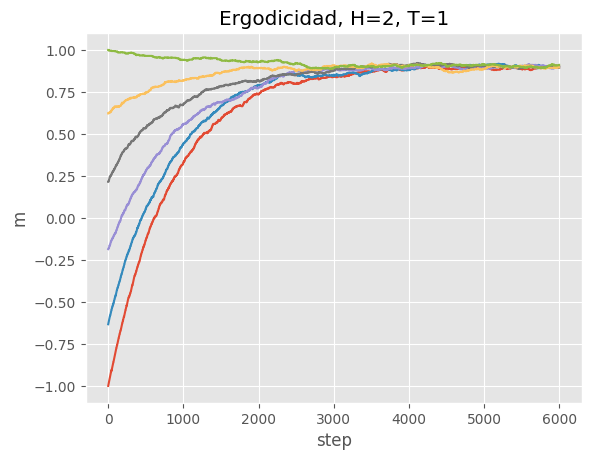

In [5]:
def test_ergodicidad(N, T, q=1, J=0, proporcion_up=0.5, H=0, steps_equilibrium=2000):
    """
    Función para probar la ergodicidad del sistema Ising con vacíos.

    Parámetros:
    - N: tamaño de la red (NxN)
    - T: temperatura
    - q: fracción de sitios ocupados (1-q será la fracción de vacíos)
    - J: constante de acoplamiento
    - proporcion_up: proporción de spines hacia arriba (1=todos arriba, 0=todos abajo)
    - H: campo magnético externo
    - steps_equilibrium: pasos para alcanzar equilibrio

    Retorna:
    - array con la evolución de la magnetización durante el equilibrio
    """

    # Crear red inicial con proporción específica de spines up/down
    red_2D = np.zeros((N, N))
    total_sites = N**2

    # Llenar la red con spines según la proporción especificada
    for i in range(N):
        for j in range(N):
            if np.random.random() < proporcion_up:
                red_2D[i][j] = 1  # Spin hacia arriba
            else:
                red_2D[i][j] = -1  # Spin hacia abajo

    # Aplicar el parámetro q (crear vacíos)
    sitios_ocupados = int(q * total_sites)
    sitios_a_vaciar = total_sites - sitios_ocupados
    cont_vacios = 0

    while cont_vacios < sitios_a_vaciar:
        i = np.random.randint(0, N)
        j = np.random.randint(0, N)
        if red_2D[i][j] != 0:  # Si el sitio está ocupado
            red_2D[i][j] = 0   # Crear vacío
            cont_vacios += 1

    # Array para la magnetización
    magnetizacion = np.zeros(steps_equilibrium)

    # Proceso de equilibrio con algoritmo de Metropolis
    for step in range(steps_equilibrium):
        # Seleccionar sitio aleatorio
        i = np.random.randint(0, N)
        j = np.random.randint(0, N)

        # Solo intentar flip si el sitio está ocupado
        if red_2D[i][j] != 0:
            # Calcular cambio de energía
            Delta_E = -2 * energy_2D(red_2D, i, j, H, N, J)

            # Criterio de Metropolis
            expo = -Delta_E / T
            p = min(1, np.exp(expo))

            if np.random.random() < p:
                red_2D[i][j] *= -1  # Flip del spin

        # Calcular y guardar magnetización
        magnetizacion[step] = red_2D.sum() / sitios_ocupados if sitios_ocupados > 0 else 0

    return magnetizacion

for proporcion in [0,0.2,0.4,0.6,0.8,1.0]:
    ergo = test_ergodicidad(N=30, T=1, q=1,J=0,H=1.5,proporcion_up=proporcion,steps_equilibrium=6000)
    plt.plot(ergo)


plt.title('Ergodicidad, H=2, T=1')
plt.xlabel('step')
plt.ylabel('m')
plt.show()

# Paramagnético J=0

## Z = 2 - Red Unidimensional


q = 1


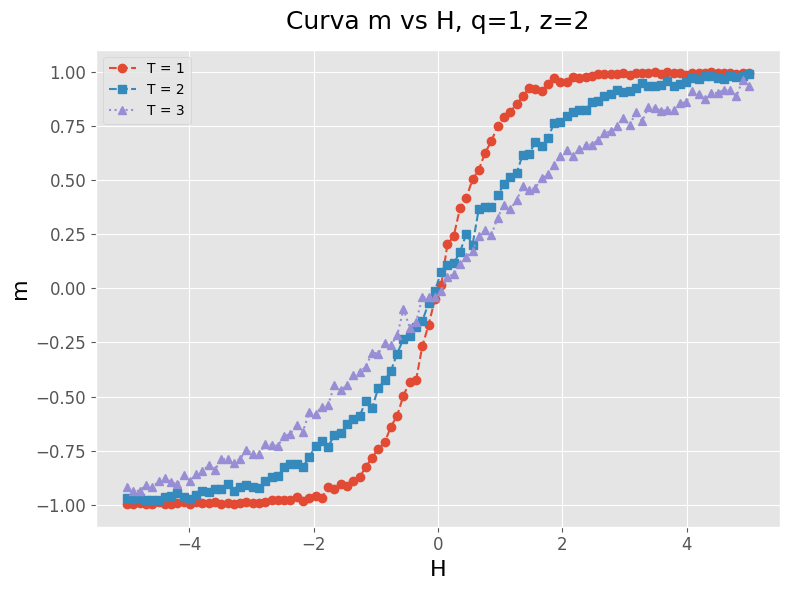

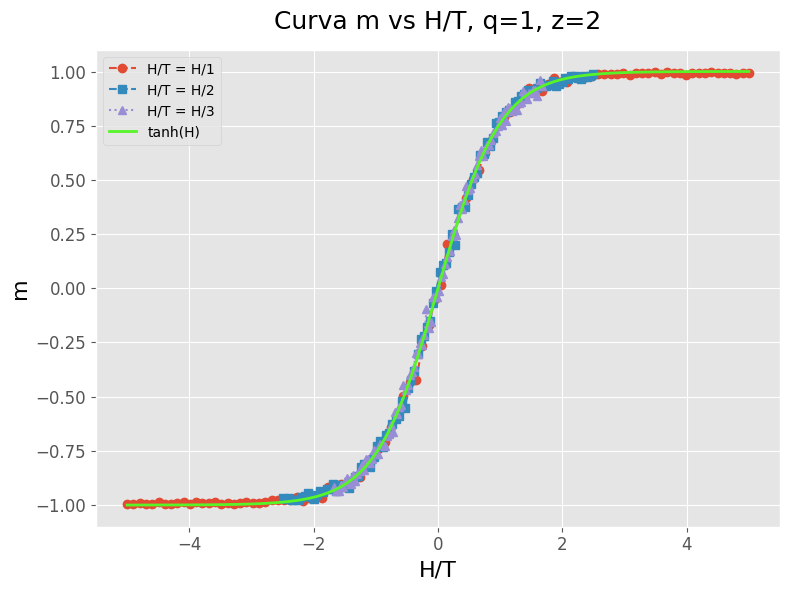

q = 0.5


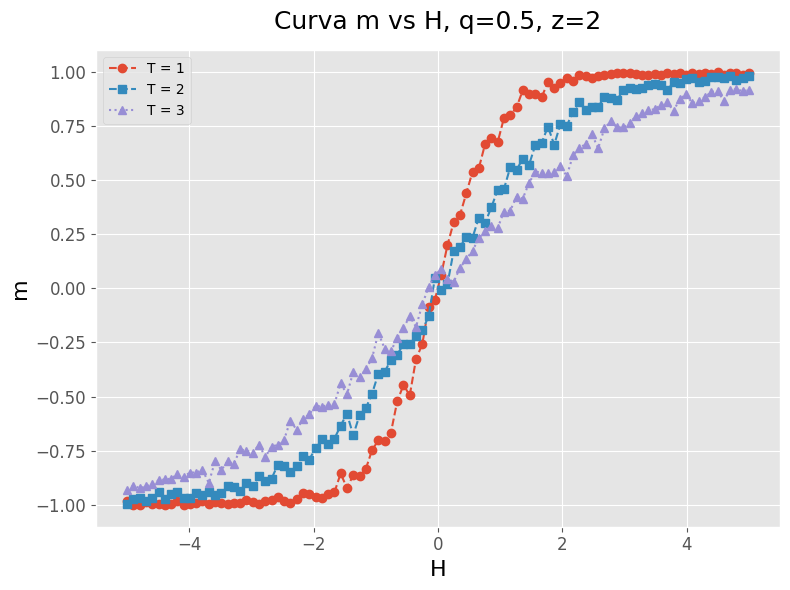

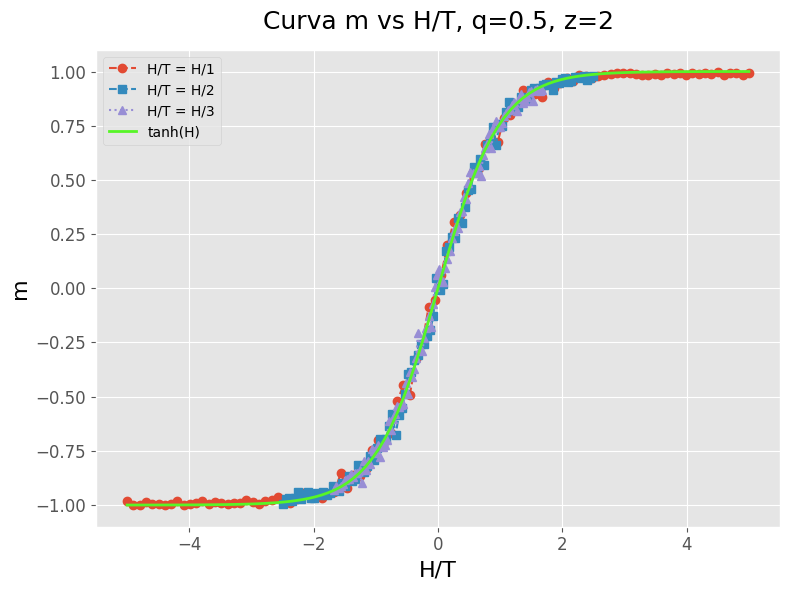

q = 0.2


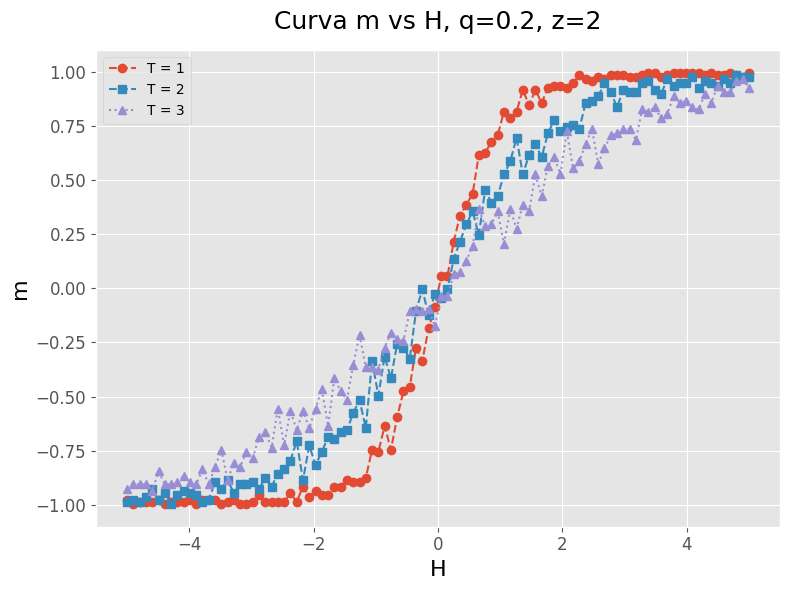

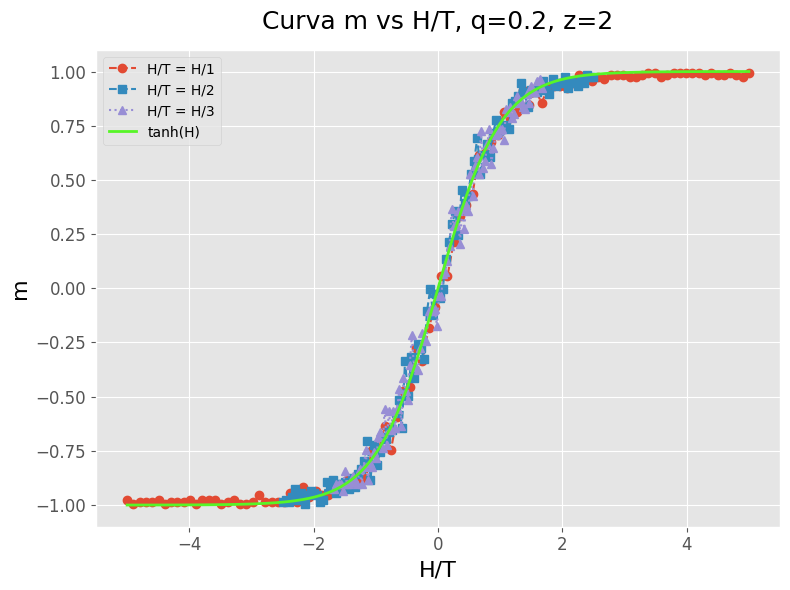

In [52]:
T = [1,2,3]
H = np.linspace(-5,5,100)

for q in [1, 0.5, 0.2]:
    print('q =',q)
    m1 = ising(H, T=T[0], q=q)
    m2 = ising(H, T=T[1], q=q)
    m3 = ising(H, T=T[2], q=q)

    grafica1(H,m1,m2,m3,T,q,z=2)

    print("==============================================================================================")

## Z = 3 -- Red Hexagonal

q = 1


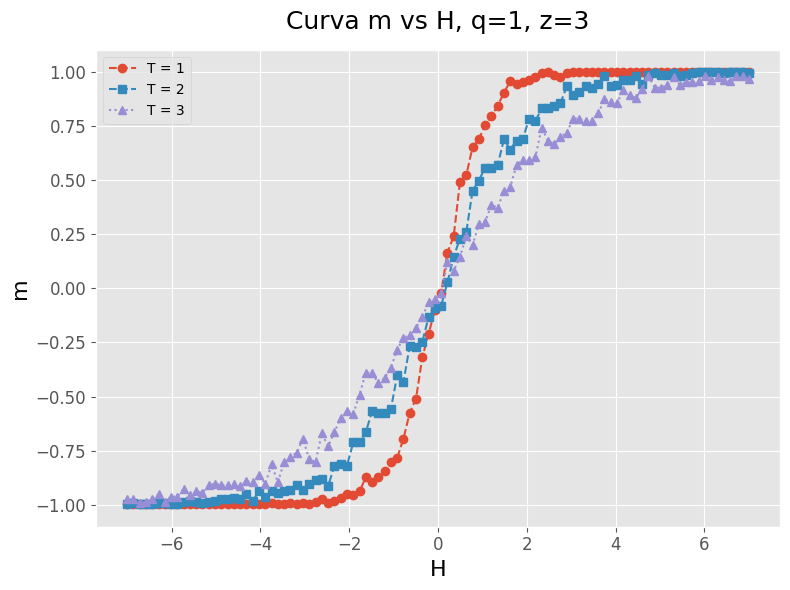

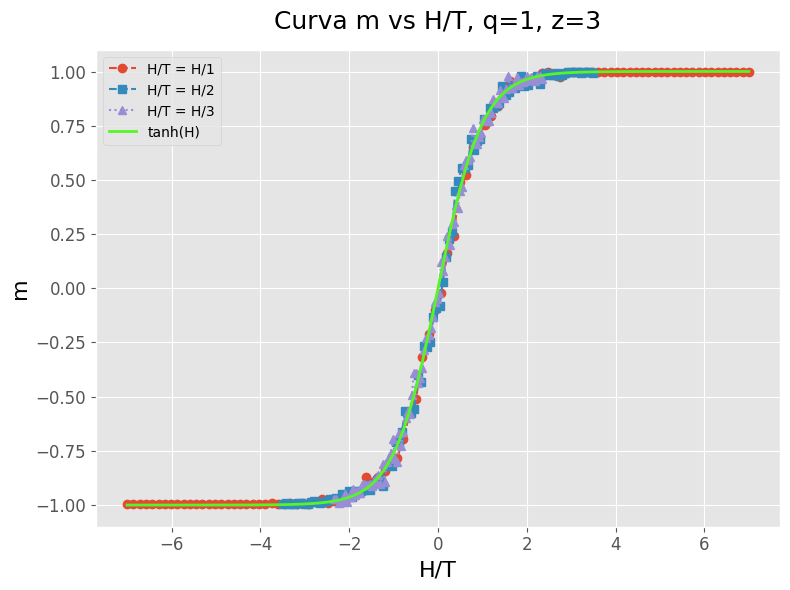

q = 0.5


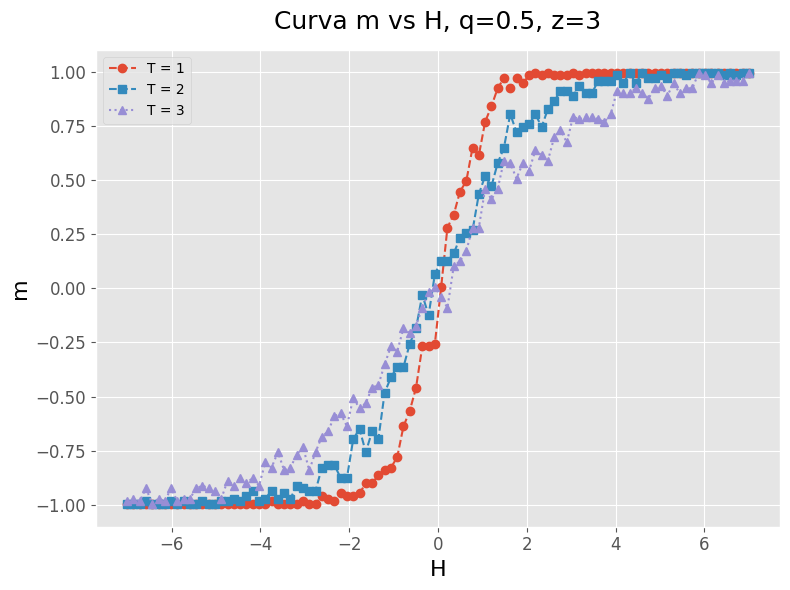

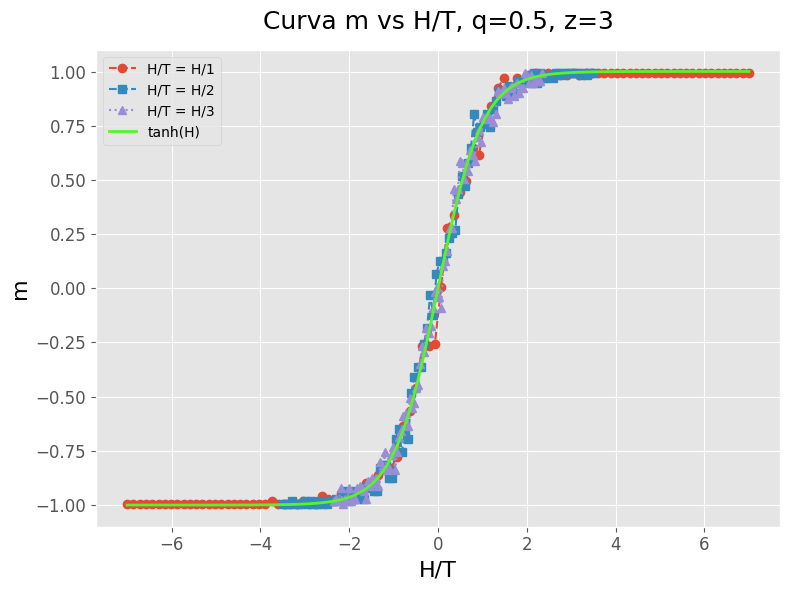

q = 0.2


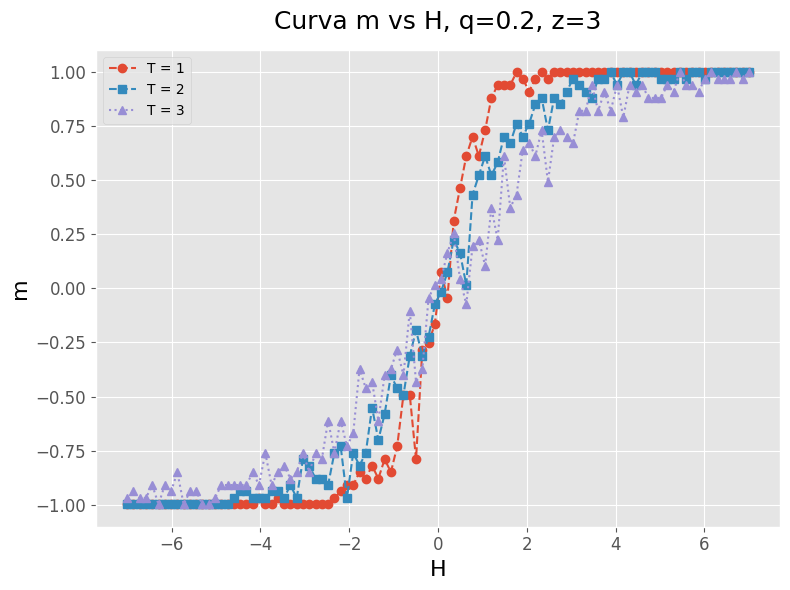

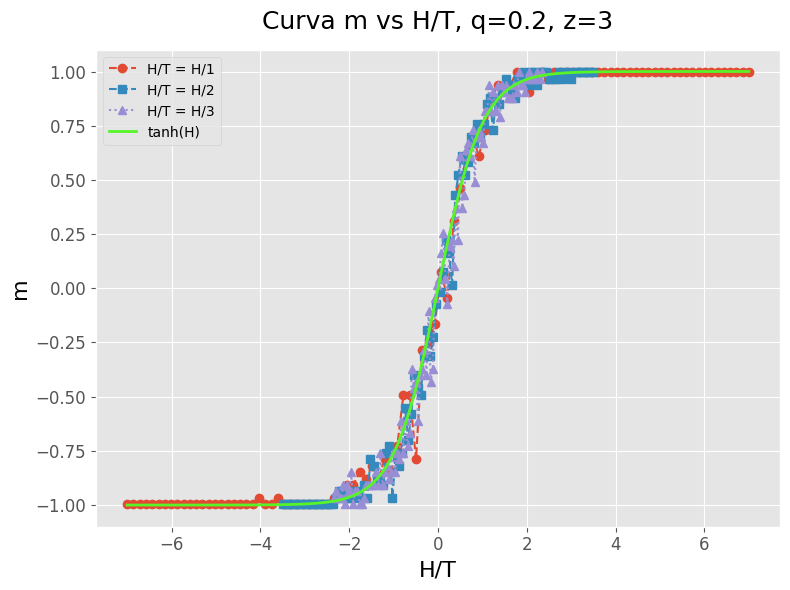

In [7]:
T = [1,2,3]
H = np.linspace(-7,7,100)
# q = 1

for q in [1, 0.5, 0.2]:
    print('q =',q)
    m1 = isingHexParamagnetico(N=12, T=T[0], q=q)
    m2 = isingHexParamagnetico(N=12, T=T[1], q=q)
    m3 = isingHexParamagnetico(N=12, T=T[2], q=q)

    grafica1(H,m1,m2,m3,T,q,z=3)

    print("==============================================================================================")

## Z = 4  -- Red bidimensional


q = 1


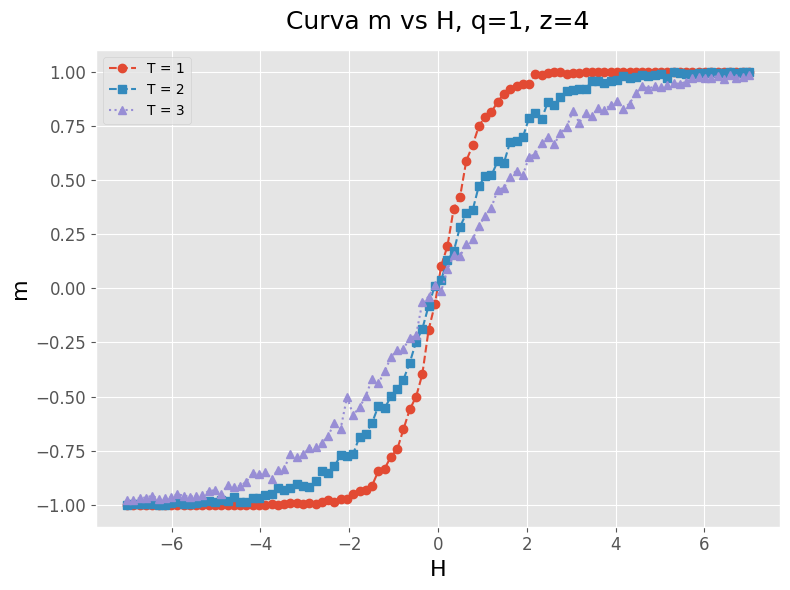

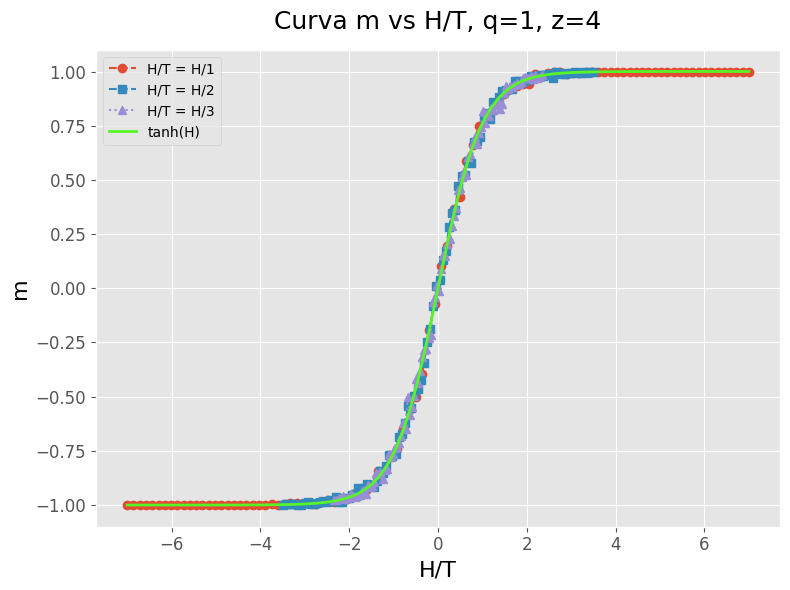

q = 0.5


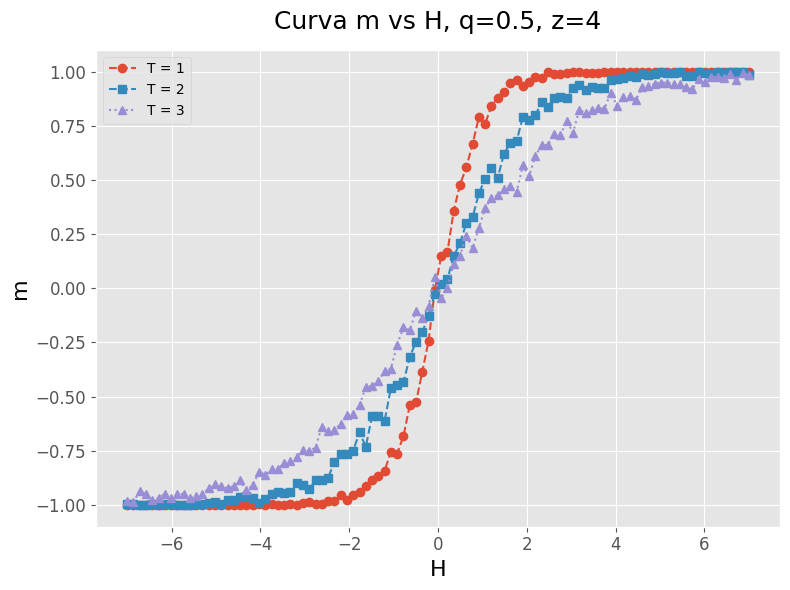

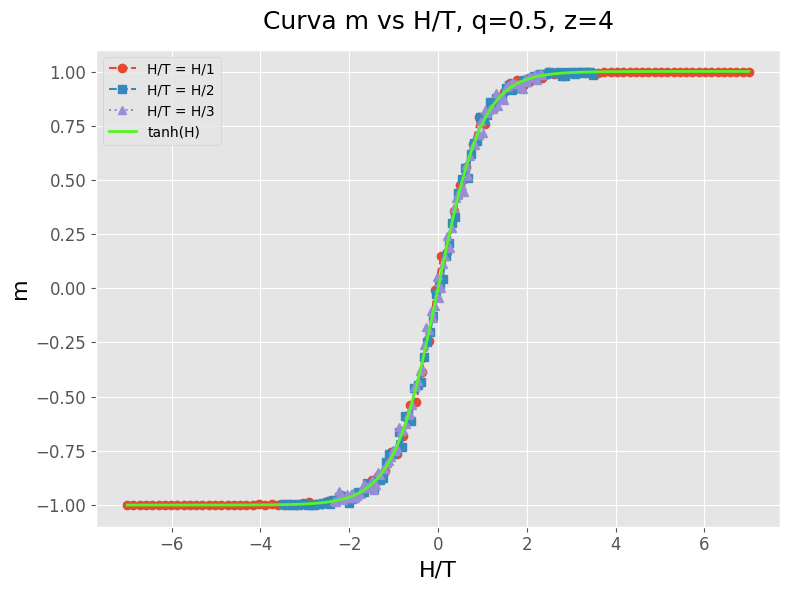

q = 0.2


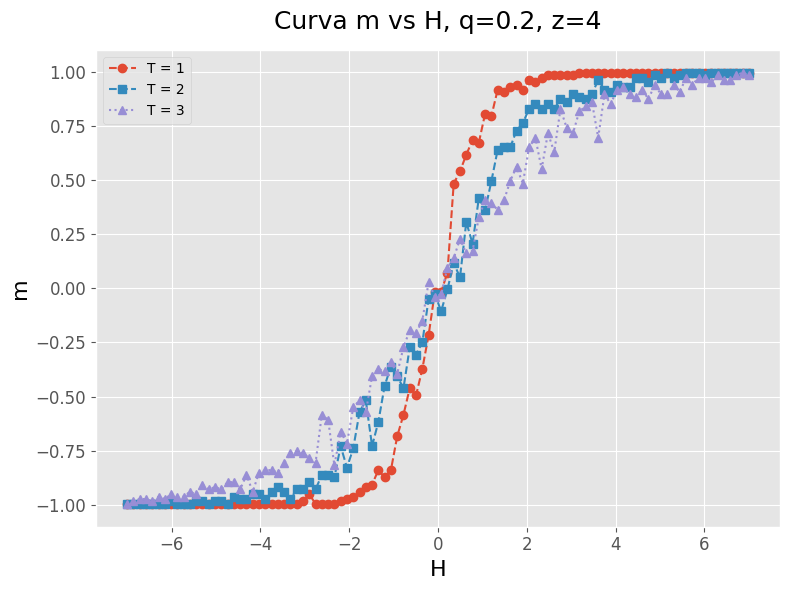

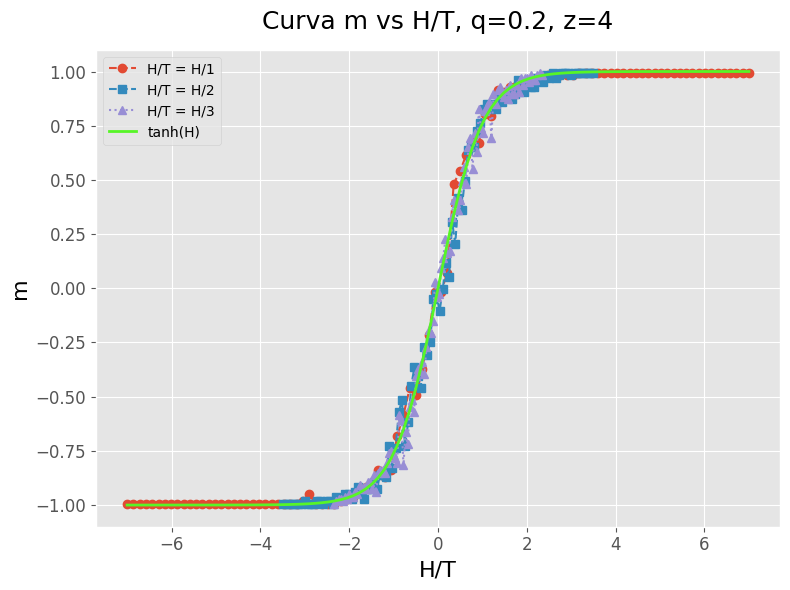

In [8]:
T = [1,2,3]
H = np.linspace(-7,7,100)
# q = 1

for q in [1, 0.5, 0.2]:
    print('q =',q)
    m1 = ising4Paramagnetico(N=30, T=T[0], q=q)
    m2 = ising4Paramagnetico(N=30, T=T[1], q=q)
    m3 = ising4Paramagnetico(N=30, T=T[2], q=q)

    grafica1(H,m1,m2,m3,T,q,z=4)

    print("==============================================================================================")

In [10]:
def energiaPasos2(N,H,T=1,q=1,J=0):
    # Caso red unidimensional
    red_1D = np.random.choice([-1, 1], size=(N))

    cont = 0
    while (N-cont)/N >= q:
        I = np.random.randint(0,N)
        if red_1D[I] != 0:
            red_1D[I] = 0
            cont += 1

    # Pasos para el equilibrio proporcional al numero de nodos
    steps_to_equilibrium = 5*N

    E_system = np.zeros(steps_to_equilibrium)

    for step in range(steps_to_equilibrium):
        i = np.random.randint(0,N)
        Delta_E = -2*energy_1D(red_1D,i,H,N,J)

        expo = -Delta_E/T
        p = min(1,np.exp(expo))

        if (np.random.random() < p):
            red_1D[i] *= -1

        E_total = 0
        for k in range(N):
            E_total += energy_1D(red_1D, k, H, J)

        E_system[step] = E_total

    return E_system

def energiaPasosHex(N, H, T=1, q=1, J=0):
    # Caso red hexagonal
    red_hex = redHex(N, [-1, 1], q)
    red_size = red_hex.shape[0]  # Tamaño de la red

    # Contar sitios ocupados
    total_occupied = np.count_nonzero(red_hex)

    steps_to_equilibrium = 5000
    E_system = np.zeros(steps_to_equilibrium)

    for step in range(steps_to_equilibrium):
        i = np.random.randint(0, red_size)
        j = np.random.randint(0, red_size)

        # Solo procesar sitios ocupados
        if red_hex[i, j] != 0:
            Delta_E = -2 * energy_hex(red_hex, i, j, H, red_size, J)

            expo = -Delta_E / T
            p = min(1, np.exp(expo))

            if np.random.random() < p:
                red_hex[i, j] *= -1

        # Calcular energía total del sistema
        E_total = 0
        for x in range(red_size):
            for y in range(red_size):
                if red_hex[x, y] != 0:  # Solo calcular para sitios ocupados
                    E_total += energy_hex(red_hex, x, y, H, red_size, J)

        E_system[step] = E_total

    return E_system

def energiaPasos4(N, H, T=1, q=1, J=0):
    # Caso red bidimensional
    red_2D = np.random.choice([-1, 1], size=(N, N))

    cont = 0
    total_spines = N**2
    while (total_spines - cont) / total_spines >= q:
        i = np.random.randint(0, N)
        j = np.random.randint(0, N)
        if red_2D[i][j] != 0:
            red_2D[i][j] = 0
            cont += 1

    steps_to_equilibrium = 2000
    E_system = np.zeros(steps_to_equilibrium)

    for step in range(steps_to_equilibrium):
        i = np.random.randint(0, N)
        j = np.random.randint(0, N)
        Delta_E = -2 * energy_2D(red_2D, i, j, H, N, J)

        expo = -Delta_E / T
        p = min(1, np.exp(expo))

        if np.random.random() < p:
            red_2D[i][j] *= -1

        E_total = 0
        for x in range(N):
            for y in range(N):
                E_total += energy_2D(red_2D, x, y, H, N, J)

        E_system[step] = E_total

    return E_system

def energiaPasos8(N, H, T=1, q=1, J=0):
    # Caso red BCC
    red_3D = redCubica(N, q)  # Ya crea la red BCC con vacíos aplicados

    steps_to_equilibrium = 10000
    E_system = np.zeros(steps_to_equilibrium)

    for step in range(steps_to_equilibrium):
        i = np.random.randint(0, N)
        j = np.random.randint(0, N)
        k = np.random.randint(0, N)

        if red_3D[i][j][k] != 0:  # Solo si el sitio está ocupado
            Delta_E = -2 * energy_3D(red_3D, i, j, k, H, N, J)
            expo = -Delta_E / T
            p = min(1, np.exp(expo))

            if np.random.random() < p:
                red_3D[i][j][k] *= -1

        # Calcular energía total del sistema
        E_total = 0
        for x in range(N):
            for y in range(N):
                for z in range(N):
                    if red_3D[x][y][z] != 0:  # Solo calcular energía de sitios ocupados
                        E_total += energy_3D(red_3D, x, y, z, H, N, J)

        E_system[step] = E_total / 2  # Dividir por 2 para evitar doble conteo de interacciones

    return E_system


In [11]:
def grafEnergiaPasos(E1,E2,E3,T,q,z):

    plt.style.use('ggplot')

    # Crear figura con 1 sola gráfica
    fig, ax = plt.subplots()

    # =====================
    # Gráfica: Energía vs pasos de Monte Carlo
    # =====================
    ax.plot(E1, '-.', label=f'T = {T[0]}',linewidth=1.3)
    ax.plot(E2, '-.', label=f'T = {T[1]}',linewidth=1.3)
    ax.plot(E3, '-.', label=f'T = {T[2]}',linewidth=1.3)

    ax.set_xlabel('Pasos Monte Carlo', color='black', fontsize=10)
    ax.set_ylabel('Energía', color='black', fontsize=10)

    #ax.set_title(f'Pasos Monte Carlo vs Energía total, q={q}, z ={z}', fontsize=14, color='black', pad=8)

    ax.legend()
    ax.grid(True)
    ax.tick_params(axis='both', labelsize=12)

    plt.tight_layout()
    plt.show()

### Z = 2

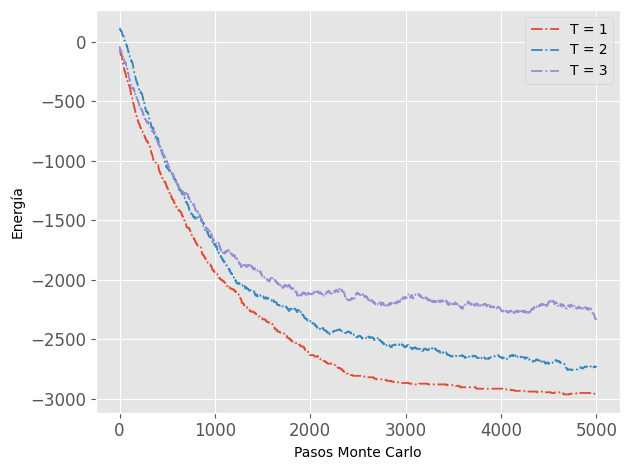

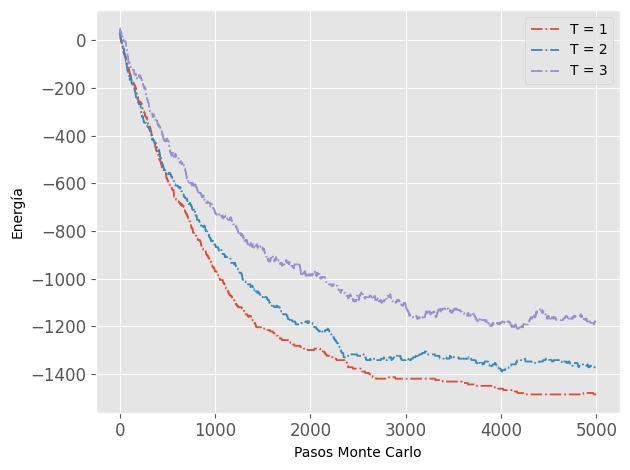

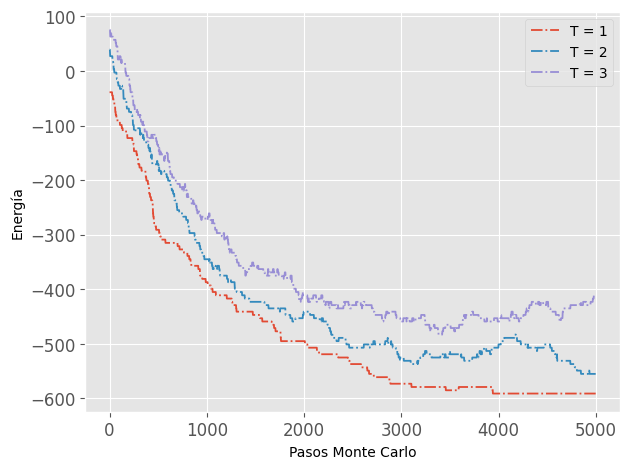

In [12]:
N = 1000
T = [1,2,3]

for q in [1, 0.5, 0.2]:
    E1 = energiaPasos2(N,H=3,T=1,q=q,J=0)
    E2 = energiaPasos2(N,H=3,T=2,q=q,J=0)
    E3 = energiaPasos2(N,H=3,T=3,q=q,J=0)

    grafEnergiaPasos(E1,E2,E3,T,q=q,z=2)
    print()
    print()


### Z = 3

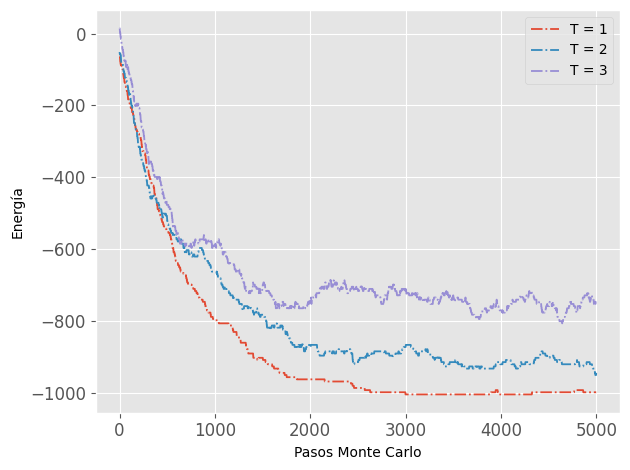

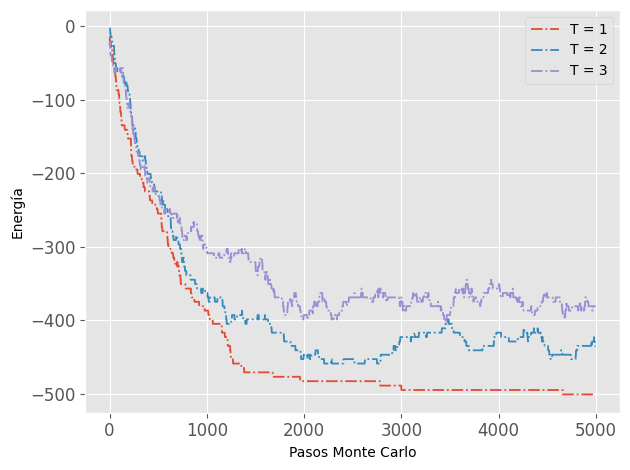

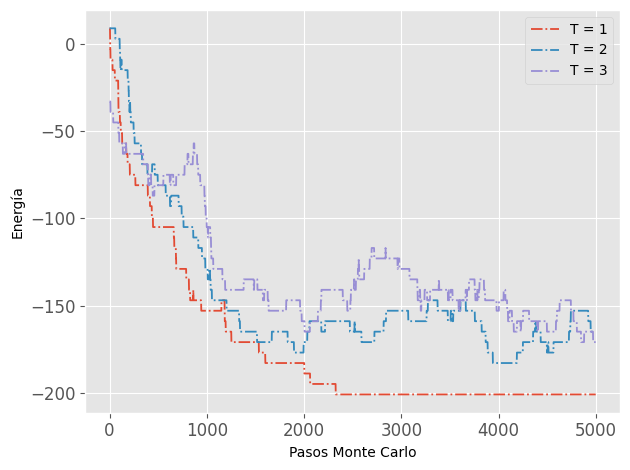

In [13]:
N = 12 # Numero de hexagonos
T = [1,2,3]

for q in [1, 0.5, 0.2]:
    E1 = energiaPasosHex(N,H=3,T=1,q=q,J=0)
    E2 = energiaPasosHex(N,H=3,T=2,q=q,J=0)
    E3 = energiaPasosHex(N,H=3,T=3,q=q,J=0)

    grafEnergiaPasos(E1,E2,E3,T,q=q,z=3)
    print()
    print()

### Z = 4

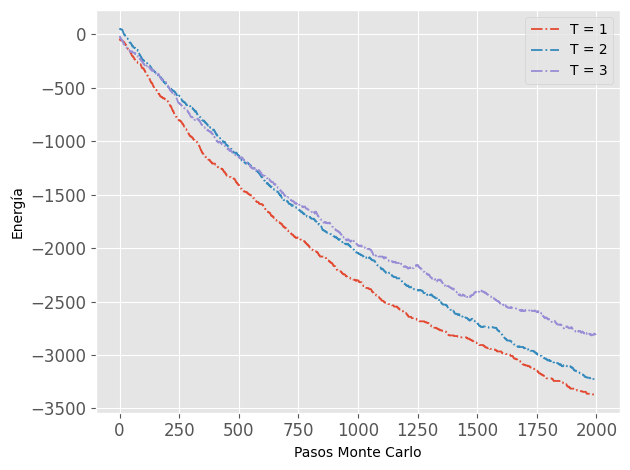

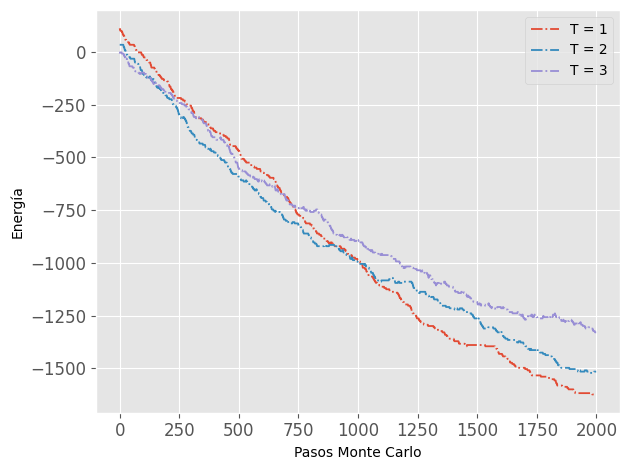

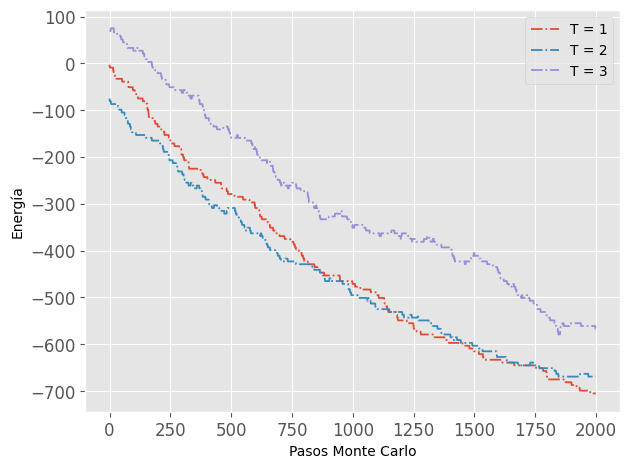

In [14]:
N = 40
T = [1,2,3]

for q in [1, 0.5, 0.2]:
    E1 = energiaPasos4(N,H=3,T=1,q=q,J=0)
    E2 = energiaPasos4(N,H=3,T=2,q=q,J=0)
    E3 = energiaPasos4(N,H=3,T=3,q=q,J=0)

    grafEnergiaPasos(E1,E2,E3,T,q=q,z=4)
    print()
    print()

### Z = 8

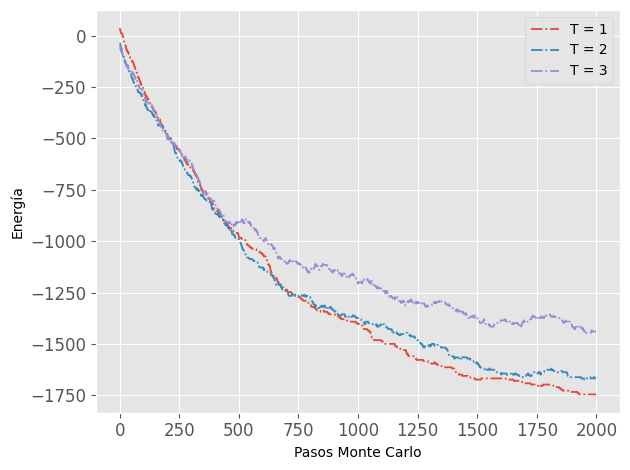

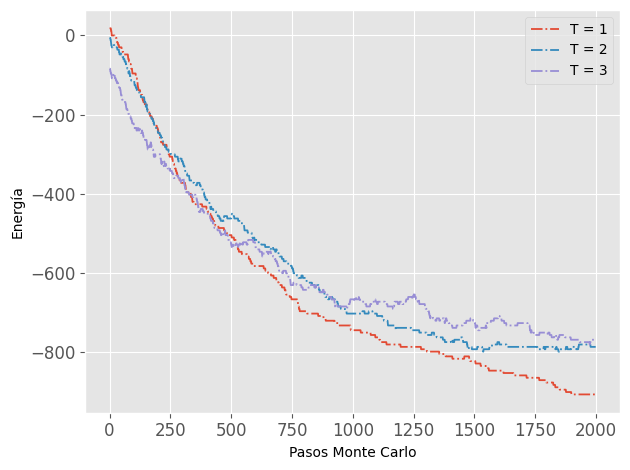

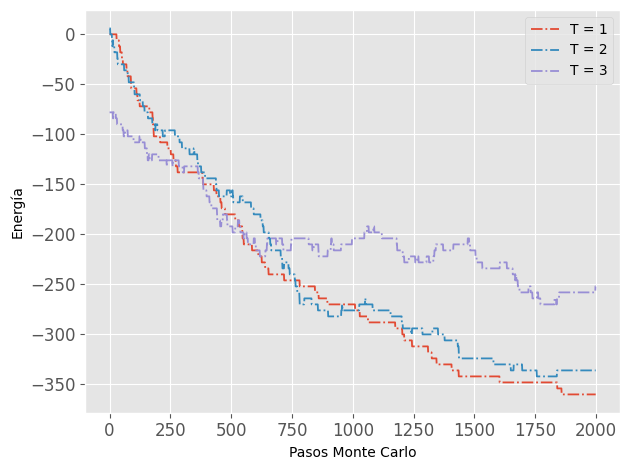

In [15]:
N = 25
T = [1,2,3]

for q in [1, 0.5, 0.2]:
    E1 = energiaPasos4(N,H=3,T=1,q=q,J=0)
    E2 = energiaPasos4(N,H=3,T=2,q=q,J=0)
    E3 = energiaPasos4(N,H=3,T=3,q=q,J=0)

    grafEnergiaPasos(E1,E2,E3,T,q=q,z=8)
    print()
    print()

# Ferromagnetico

In [36]:
def ferromagnetico2(N,T,q):
    # N = 1000
    # T = 1.5
    z=2
    red = np.random.choice([-1],size=(N))
    cont = 0
    while (N-cont)/N >= q:
        I = np.random.randint(0,N)
        if red[I] != 0:
            red[I] = 0
            cont += 1

    H_values = np.linspace(-10,10,100)

    ms_creciente = np.zeros(len(H_values))
    ms_decreciente = np.zeros(len(H_values))

    steps_to_equilibrium = 5*N
    for step in range(len(H_values)):
        for _ in range(steps_to_equilibrium):
                i = np.random.randint(0,N)

                Delta_E = -energy_1D(red,i,H_values[step],N,J=1)
                p = min(1,np.e**(-Delta_E/T))

                if (np.random.random() < p):
                    red[i] *= -1

        ms_creciente[step] = red.sum()/(N*q)


    for step in range(len(H_values)):
        for _ in range(steps_to_equilibrium):
                i = np.random.randint(0,N)

                Delta_E = -energy_1D(red,i,-H_values[step],N,J=1)
                p = min(1,np.e**(-Delta_E/T))

                if (np.random.random() < p):
                    red[i] *= -1

        ms_decreciente[step] = red.sum()/(N*q)

    plt.title(f'Curva m vs H, T={T}, q={q}, z={z}', fontsize=18, color='black', pad=15)
    plt.xlabel('H', fontsize=14, color='black')
    plt.ylabel('m', fontsize=14, color='black')
    plt.axhline(0,color='black',linestyle='--',linewidth=0.5)
    plt.axvline(0,color='black',linestyle='--',linewidth=0.5)
    plt.plot(H_values,ms_creciente, label="Campo creciente")
    plt.plot(-H_values,ms_decreciente, label="Campo decreciente")
    plt.legend()
    plt.show()

def ferromagnetico3(N,T,q):
    # N = 1000
    # T = 1.5
    z=3
    red = redHex(N,[-1],q)
    red_size = red.shape[0]  # Tamaño de la red
    total_spines = 2*N*(N+2)

    H_values = np.linspace(-10,10,100)

    ms_creciente = np.zeros(len(H_values))
    ms_decreciente = np.zeros(len(H_values))

    steps_to_equilibrium = 5000
    for step in range(len(H_values)):
        for _ in range(steps_to_equilibrium):
                i = np.random.randint(0,red_size)
                j = np.random.randint(0,red_size)

                Delta_E = -energy_hex(red,i,j,H_values[step],red_size,J=1)
                p = min(1,np.e**(-Delta_E/T))

                if (np.random.random() < p):
                    red[i][j] *= -1

        ms_creciente[step] = red.sum()/(total_spines*q)


    for step in range(len(H_values)):
        for _ in range(steps_to_equilibrium):
                i = np.random.randint(0,red_size)
                j = np.random.randint(0,red_size)

                Delta_E = -energy_hex(red,i,j,H_values[step],red_size,J=1)
                p = min(1,np.e**(-Delta_E/T))

                if (np.random.random() < p):
                    red[i][j] *= -1

        ms_decreciente[step] = red.sum()/(total_spines*q)

    plt.title(f'Curva m vs H, T={T}, q={q}, z={z}', fontsize=18, color='black', pad=15)
    plt.xlabel('H', fontsize=14, color='black')
    plt.ylabel('m', fontsize=14, color='black')
    plt.axhline(0,color='black',linestyle='--',linewidth=0.5)
    plt.axvline(0,color='black',linestyle='--',linewidth=0.5)
    plt.plot(H_values,ms_creciente, label="Campo creciente")
    plt.plot(H_values,ms_decreciente, label="Campo decreciente")
    plt.legend()
    plt.show()

def ferromagnetico4(N,T,q):
    # Red bidimensional z=4
    z=4
    red = np.random.choice([-1],size=(N,N))
    cont = 0
    total_spines = N**2
    while (total_spines-cont)/total_spines >= q:
        i = np.random.randint(0,N)
        j = np.random.randint(0,N)
        if red[i][j] != 0:
            red[i][j] = 0
            cont += 1

    H_values = np.linspace(-10,10,100)

    ms_creciente = np.zeros(len(H_values))
    ms_decreciente = np.zeros(len(H_values))

    steps_to_equilibrium = 2000
    for step in range(len(H_values)):
        for _ in range(steps_to_equilibrium):
                i = np.random.randint(0,N)
                j = np.random.randint(0,N)

                Delta_E = -energy_2D(red,i,j,H_values[step],N,J=1)
                p = min(1,np.e**(-Delta_E/T))

                if (np.random.random() < p):
                    red[i][j] *= -1

        ms_creciente[step] = red.sum()/(total_spines*q)


    for step in range(len(H_values)):
        for _ in range(steps_to_equilibrium):
                i = np.random.randint(0,N)
                j = np.random.randint(0,N)

                Delta_E = -energy_2D(red,i,j,-H_values[step],N,J=1)
                p = min(1,np.e**(-Delta_E/T))

                if (np.random.random() < p):
                    red[i][j] *= -1

        ms_decreciente[step] = red.sum()/(total_spines*q)

    plt.title(f'Curva m vs H, T={T}, q={q} z={z}', fontsize=18, color='black', pad=15)
    plt.xlabel('H', fontsize=14, color='black')
    plt.ylabel('m', fontsize=14, color='black')
    plt.axhline(0,color='black',linestyle='--',linewidth=0.5)
    plt.axvline(0,color='black',linestyle='--',linewidth=0.5)
    plt.plot(H_values,ms_creciente, label="Campo creciente")
    plt.plot(-H_values,ms_decreciente, label="Campo decreciente")
    plt.legend()
    plt.show()

def ferromagnetico8(N,T,q):
    # Red BCC z=8 (8 vecinos diagonales)
    z=8
    red = redCubica(N, q,[-1])

    H_values = np.linspace(-8,8,80)
    ms_creciente = np.zeros(len(H_values))
    ms_decreciente = np.zeros(len(H_values))
    steps_to_equilibrium = 10000

    # Ciclo creciente
    for step in range(len(H_values)):
        for _ in range(steps_to_equilibrium):
            i = np.random.randint(0,N)
            j = np.random.randint(0,N)
            k = np.random.randint(0,N)

            if red[i][j][k] != 0:  # Solo si el sitio está ocupado
                Delta_E = -2*energy_3D(red,i,j,k,H_values[step],N,J=1)
                p = min(1,np.e**(-Delta_E/T))

                if (np.random.random() < p):
                    red[i][j][k] *= -1

        ms_creciente[step] = red.sum()/(q*N**3)

    # Ciclo decreciente
    for step in range(len(H_values)):
        for _ in range(steps_to_equilibrium):
            i = np.random.randint(0,N)
            j = np.random.randint(0,N)
            k = np.random.randint(0,N)

            if red[i][j][k] != 0:  # Solo si el sitio está ocupado
                Delta_E = -2*energy_3D(red,i,j,k,-H_values[step],N,J=1)
                p = min(1,np.e**(-Delta_E/T))

                if (np.random.random() < p):
                    red[i][j][k] *= -1

        ms_decreciente[step] = red.sum()/(q*N**3)

    plt.title(f'Curva m vs H, T={T}, q={q}, z={z}', fontsize=18, color='black', pad=15)
    plt.xlabel('H', fontsize=14, color='black')
    plt.ylabel('m', fontsize=14, color='black')
    plt.axhline(0,color='black',linestyle='--',linewidth=0.5)
    plt.axvline(0,color='black',linestyle='--',linewidth=0.5)
    plt.plot(H_values,ms_creciente, label="Campo creciente")
    plt.plot(-H_values,ms_decreciente, label="Campo decreciente")
    plt.legend()
    plt.show()

### Z = 2

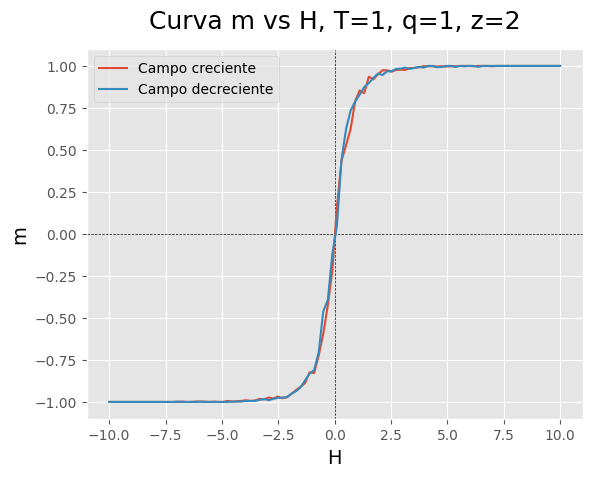

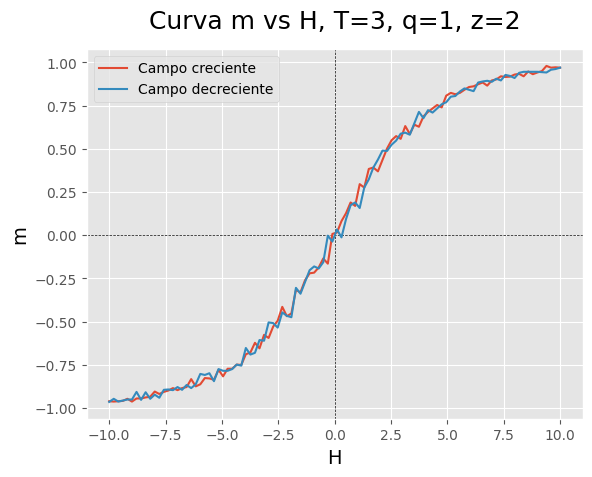

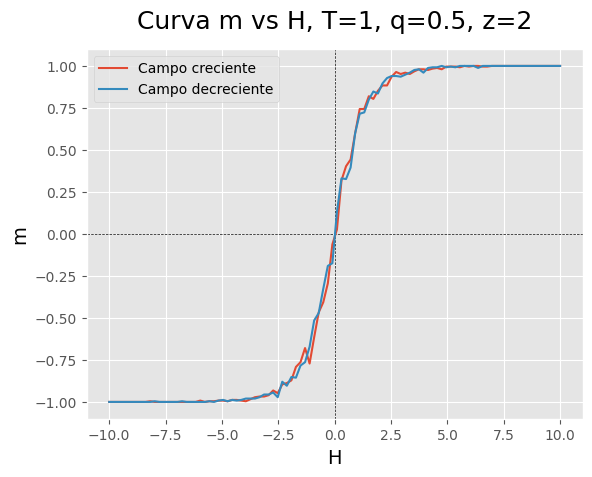

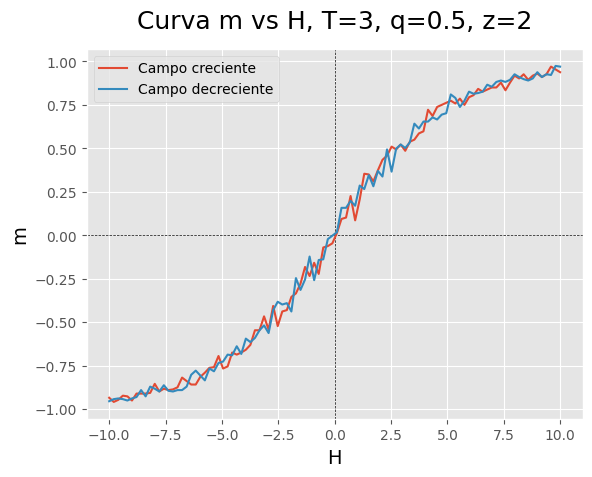

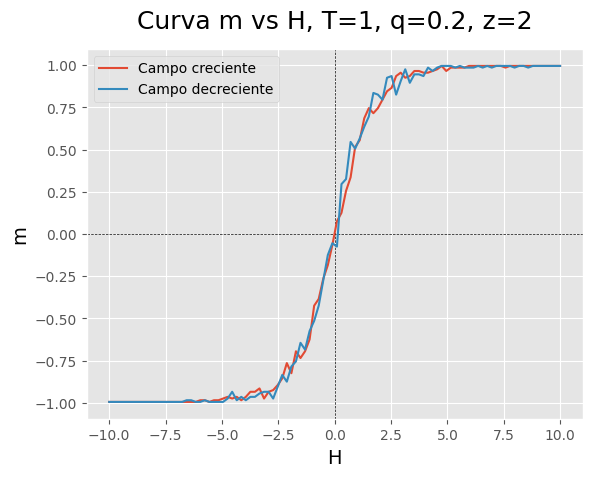

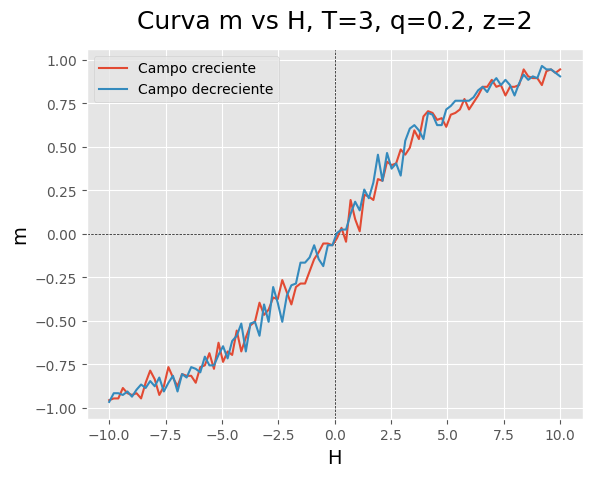

In [17]:
for q in [1,0.5, 0.2]:
    ferromagnetico2(N=1000,T=1,q=q)
    ferromagnetico2(N=1000,T=3,q=q)

    print()
    print()

### z = 3


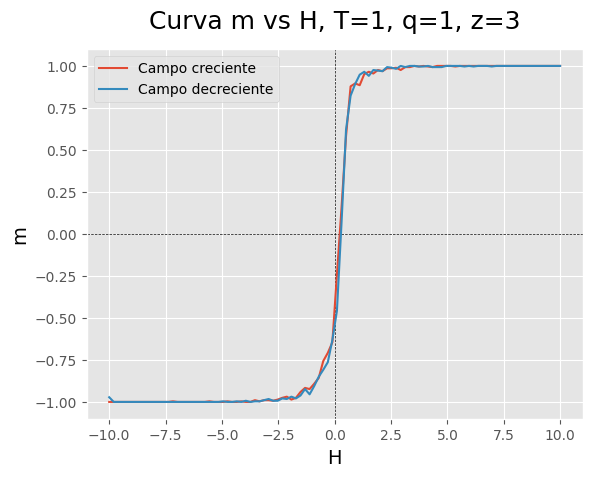

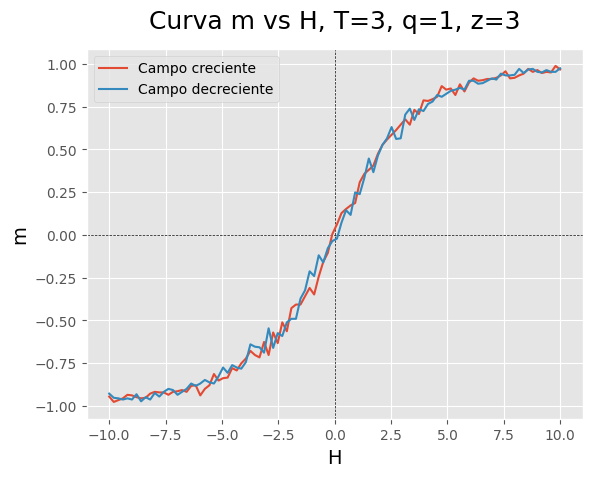

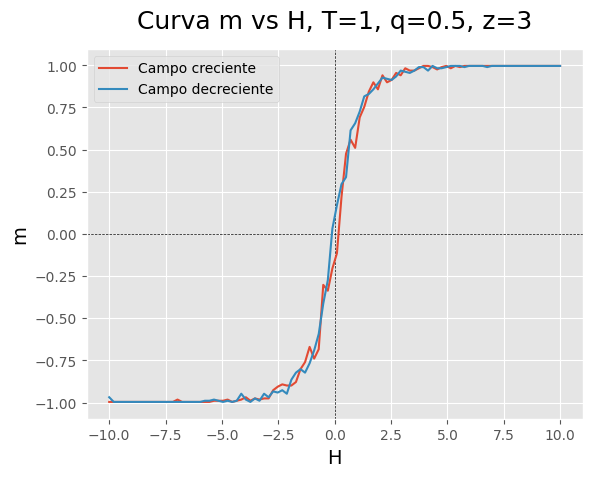

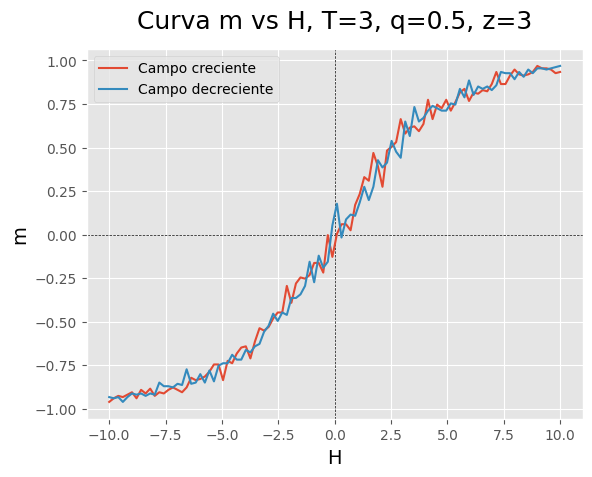

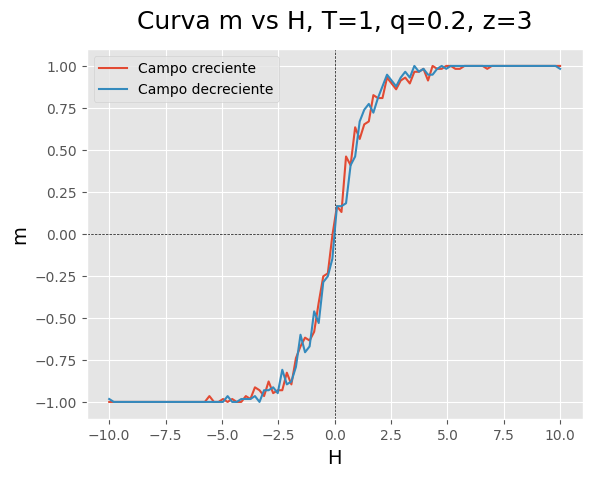

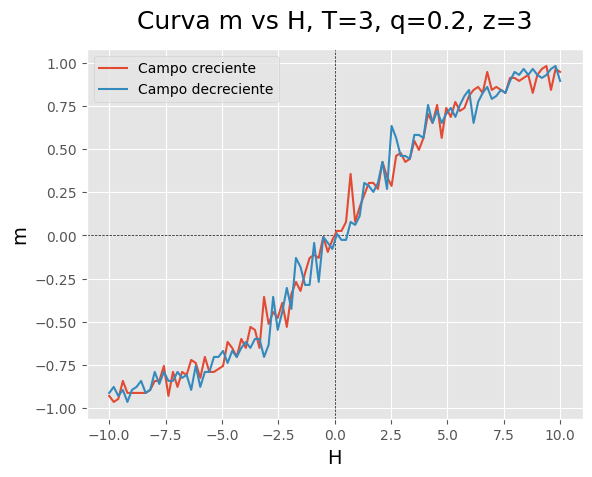

In [37]:
for q in [1,0.5, 0.2]:
    ferromagnetico3(N=16,T=1,q=q)
    ferromagnetico3(N=16,T=3,q=q)

### z = 4

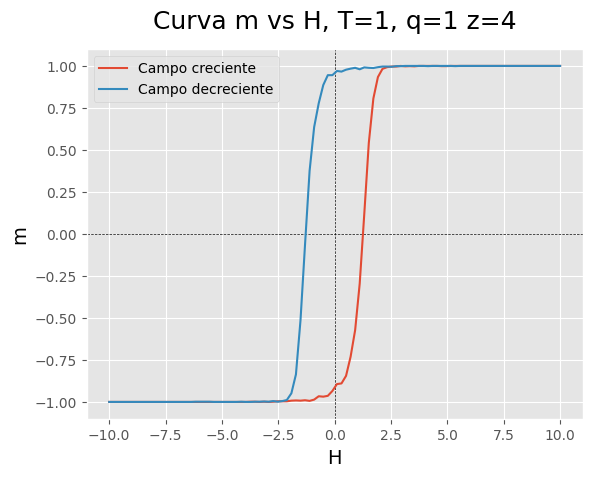

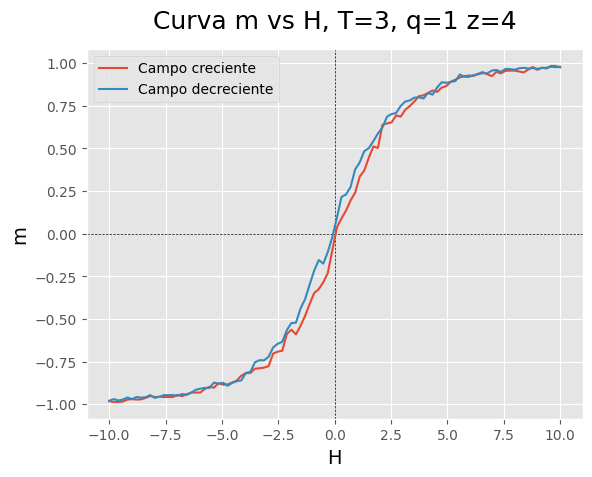

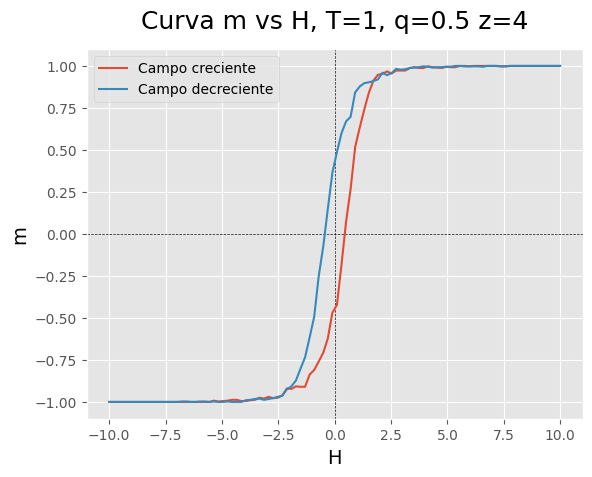

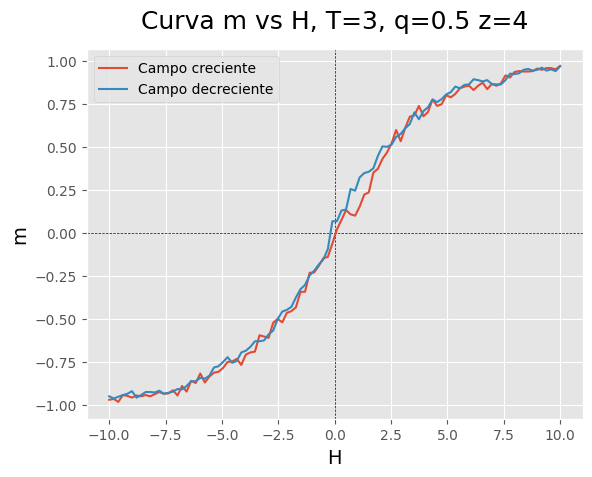

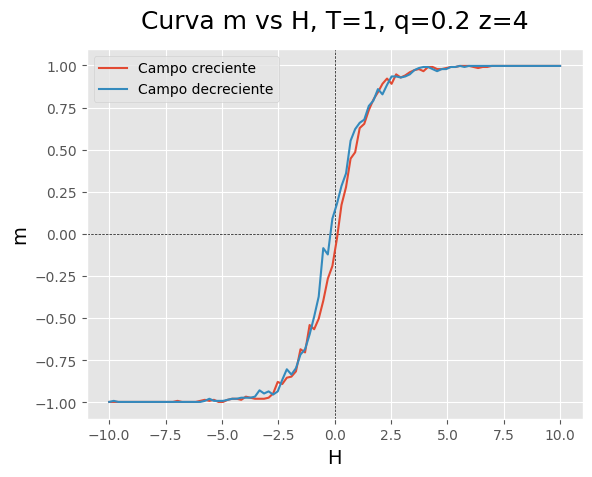

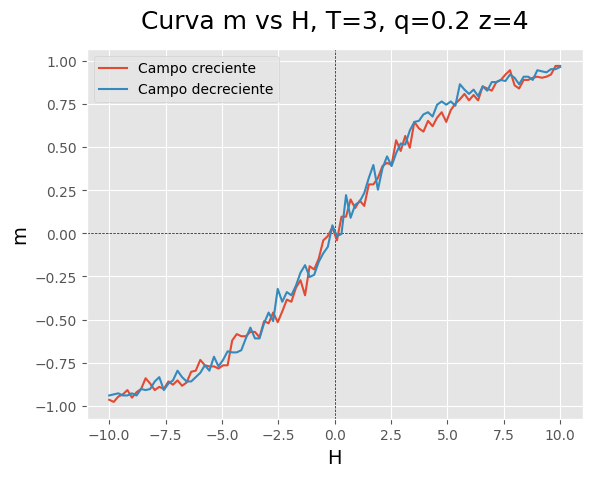

In [19]:
for q in [1,0.5, 0.2]:
    ferromagnetico4(N=40,T=1,q=q)
    ferromagnetico4(N=40,T=3,q=q)

### z = 8

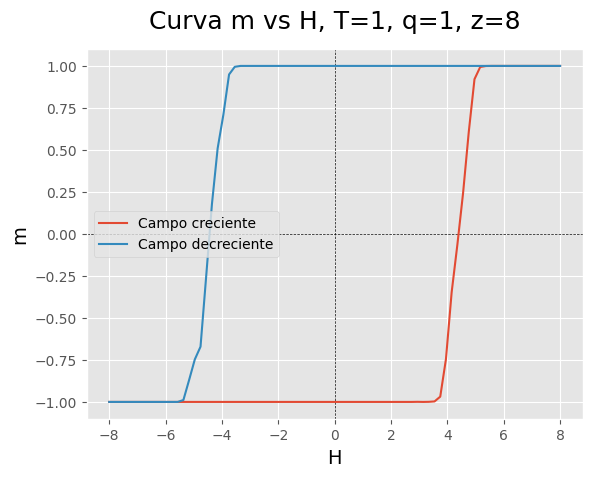

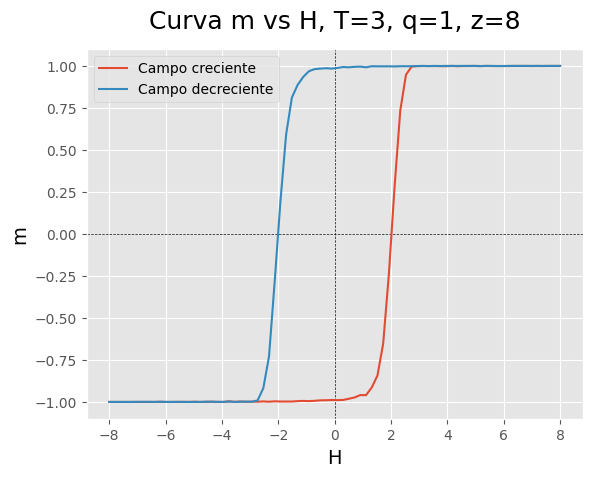

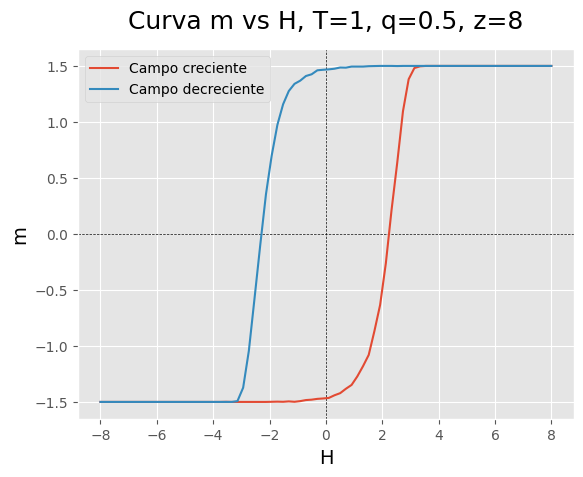

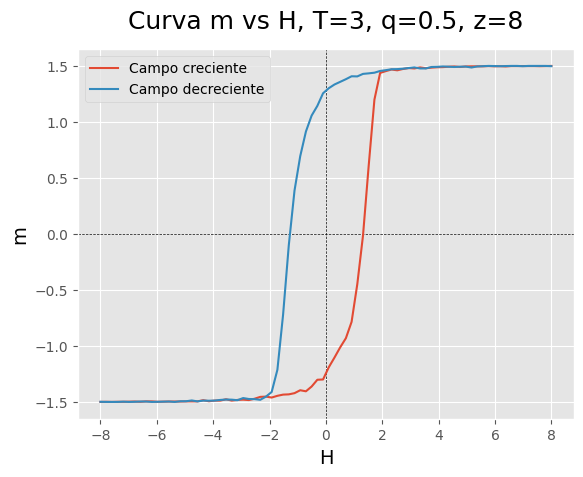

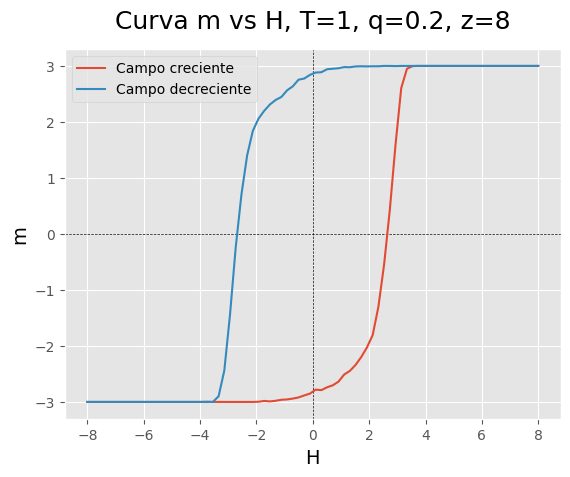

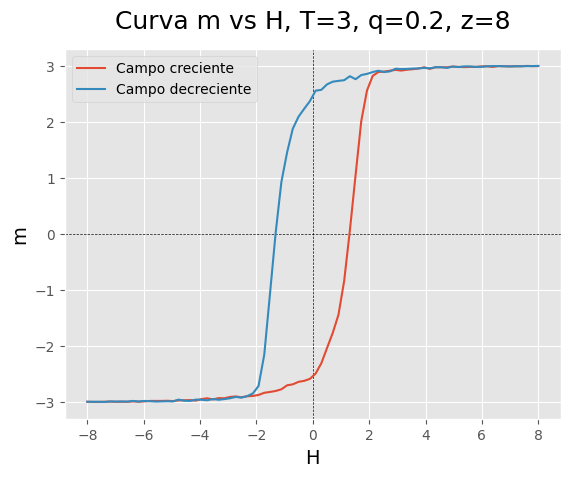

In [20]:
for q in [1,0.5, 0.2]:
    ferromagnetico8(N=15,T=1,q=q)
    ferromagnetico8(N=15,T=3,q=q)

# Cambio de fase

In [21]:
def mostrar_red(red_2D,T,q):
    """
    Muestra una red 2D con colores: rojo (+1), azul (-1), blanco (0)
    """
    from matplotlib.colors import ListedColormap
    colors = ['blue', 'white', 'red']  # -1, 0, +1
    cmap = ListedColormap(colors)

    plt.figure(figsize=(8, 8))
    plt.title(f'T = {T:.1f} -- q = {q}')
    plt.imshow(red_2D, cmap=cmap, vmin=-1, vmax=1)
    plt.axis('off')
    plt.show()

def transicion_fase(N, H, T_vals, q):
    """
    Calcula la transición de fase para el modelo Ising 2D con vacíos.

    Parámetros:
    - N: tamaño de la red (NxN)
    - H: campo magnético externo
    - T_vals: array de temperaturas a evaluar
    - q: fracción de sitios ocupados

    Retorna:
    - m_vals: array con la magnetización para cada temperatura
    """

    red_2D = np.ones((N,N))  # todos inicialmente arriba
    total_spines = N**2
    cont = 0

    # Aplicar el parámetro q (crear vacíos)
    while (total_spines-cont)/total_spines > q:
        i = np.random.randint(0,N)
        j = np.random.randint(0,N)
        if red_2D[i][j] != 0:
            red_2D[i][j] = 0
            cont += 1

    m_vals = np.zeros(len(T_vals))
    steps_to_equilibrium = 5*N**2

    # Variables para gráficas (FUERA del loop)
    T_graficas = [1,2,2.5,2.7,3,5]
    cont_grafica = 0
    graficar = True

    for idx, T in enumerate(T_vals):

        # camino hacia el equilibrio de steps_to_equilibrium pasos
        for step in range(steps_to_equilibrium):
            i = np.random.randint(0, N)
            j = np.random.randint(0, N)

            if red_2D[i][j] != 0:  # Solo si el sitio está ocupado
                Delta_E = -2 * energy_2D(red_2D, i, j, H, N, J=1)
                expo = -Delta_E / T
                p = min(1, np.exp(expo))

                if np.random.random() < p:
                    red_2D[i][j] *= -1

        # otras 1000 iteraciones para calcular el promedio de m
        m_array = np.zeros(1000)
        for step in range(1000):
            i = np.random.randint(0, N)
            j = np.random.randint(0, N)

            if red_2D[i][j] != 0:  # Solo si el sitio está ocupado
                Delta_E = -2 * energy_2D(red_2D, i, j, H, N, J=1)
                expo = -Delta_E / T
                p = min(1, np.exp(expo))

                if np.random.random() < p:
                    red_2D[i][j] *= -1

            m_array[step] = abs(red_2D.sum()) / (q * N**2)

        m_vals[idx] = np.mean(m_array)  # promedio de m

        # Graficar solo para ciertas T
        if (graficar and cont_grafica < len(T_graficas) and T >= T_graficas[cont_grafica]):
            mostrar_red(red_2D,T,q)
            cont_grafica += 1

            if cont_grafica == len(T_graficas):
                graficar = False

    return m_vals

q = 1


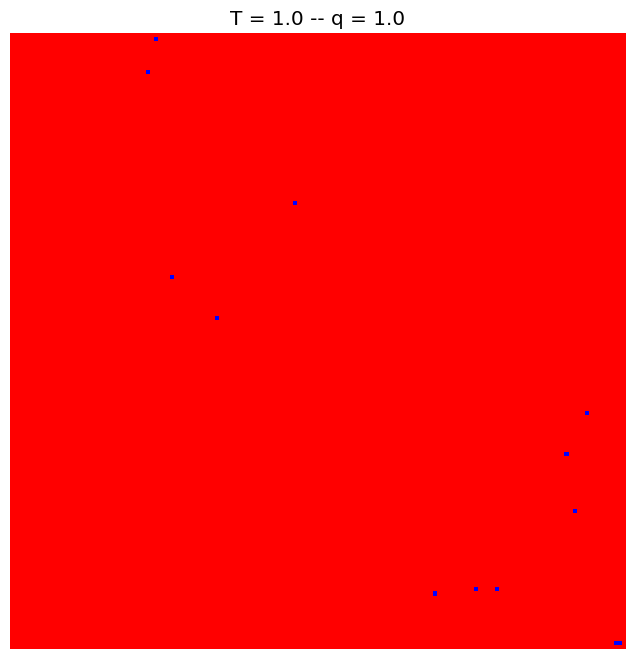

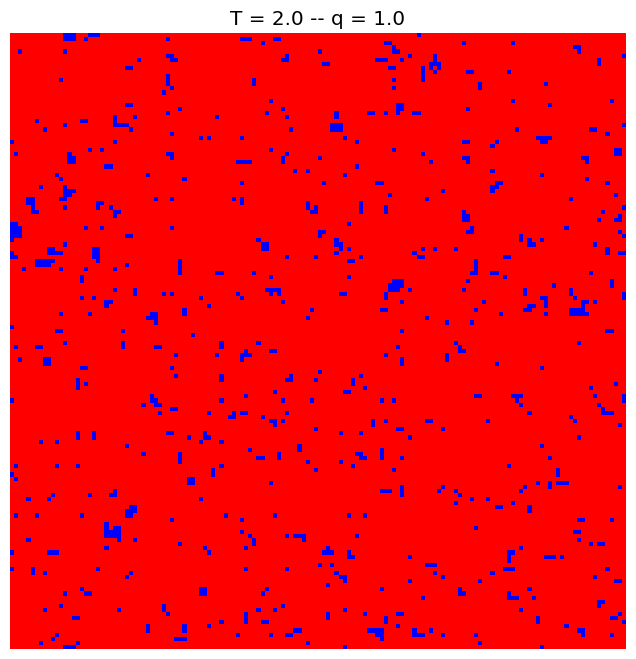

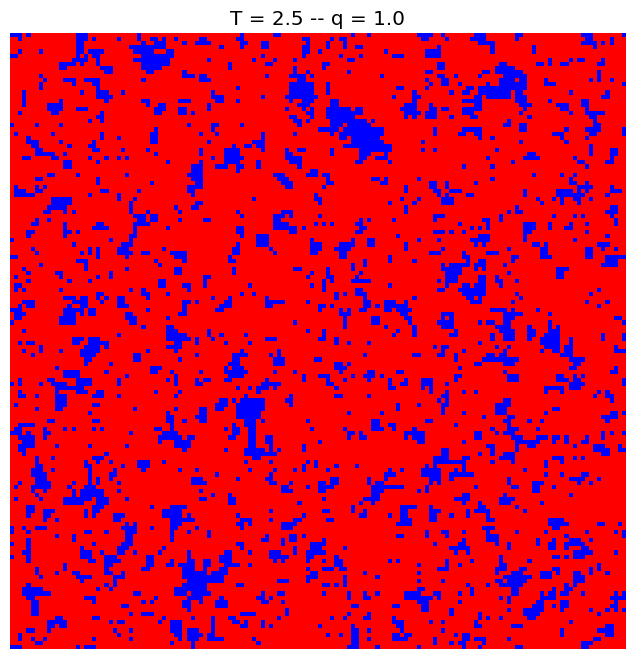

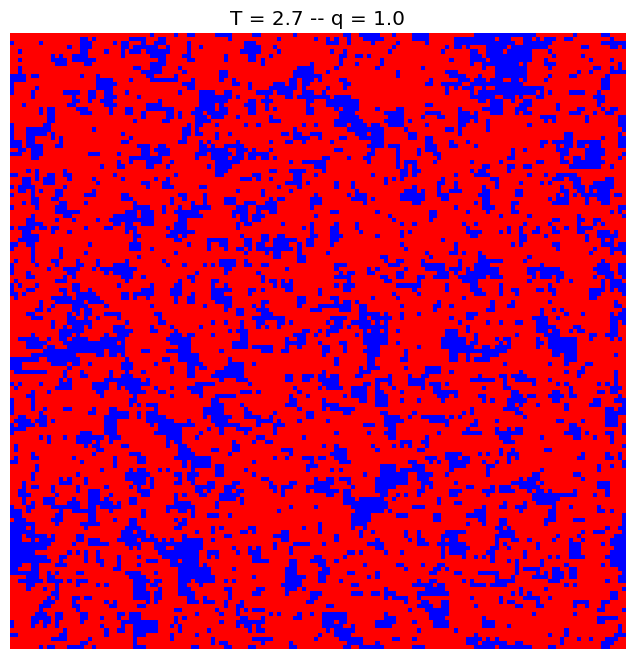

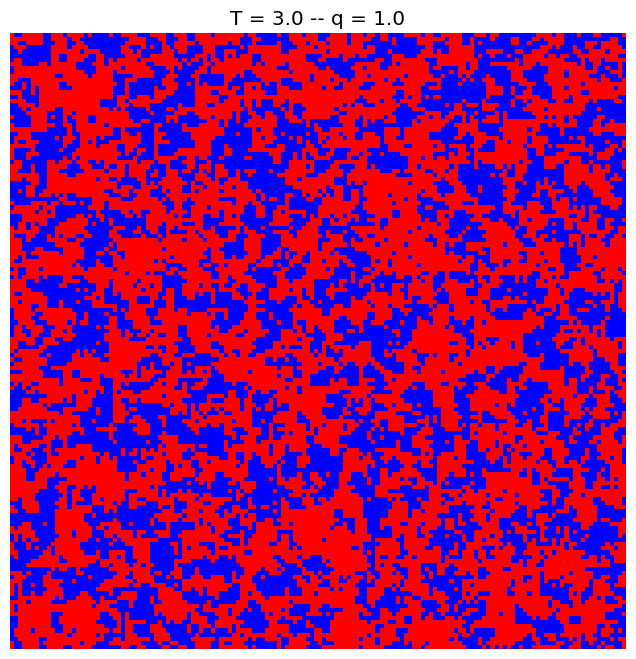

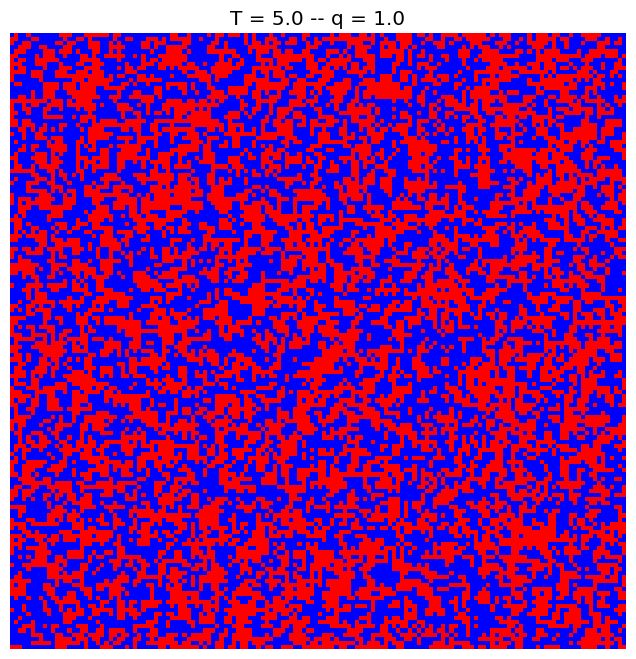



q = 0.8


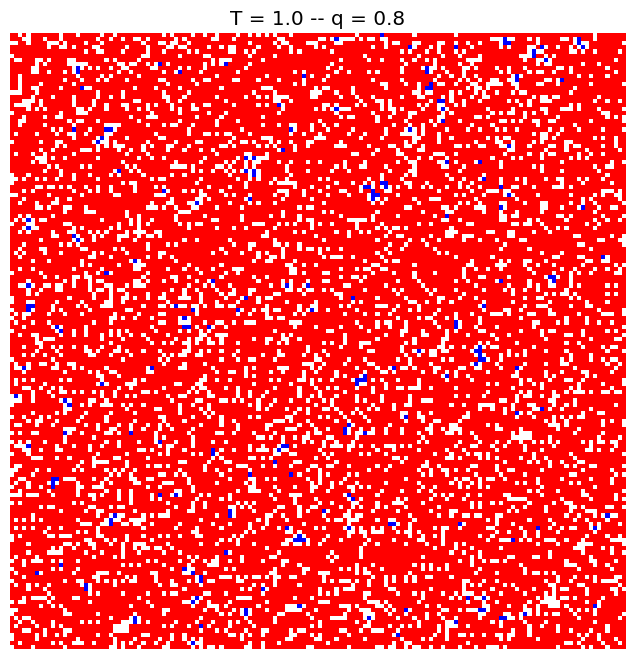

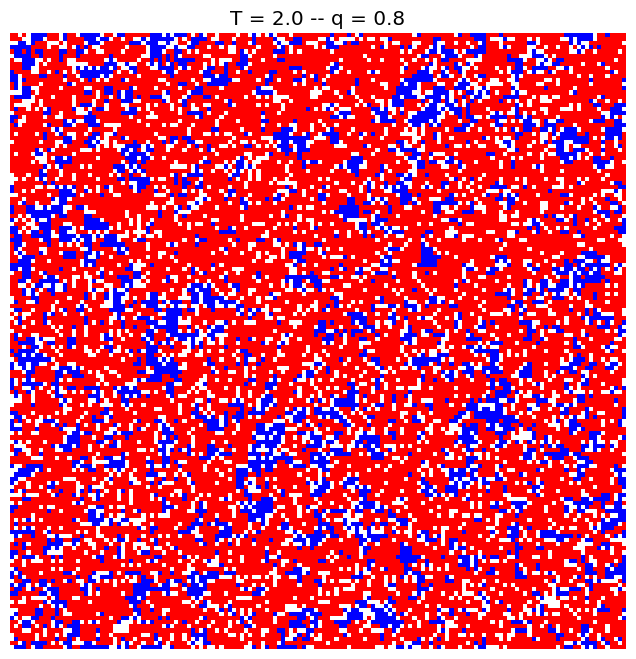

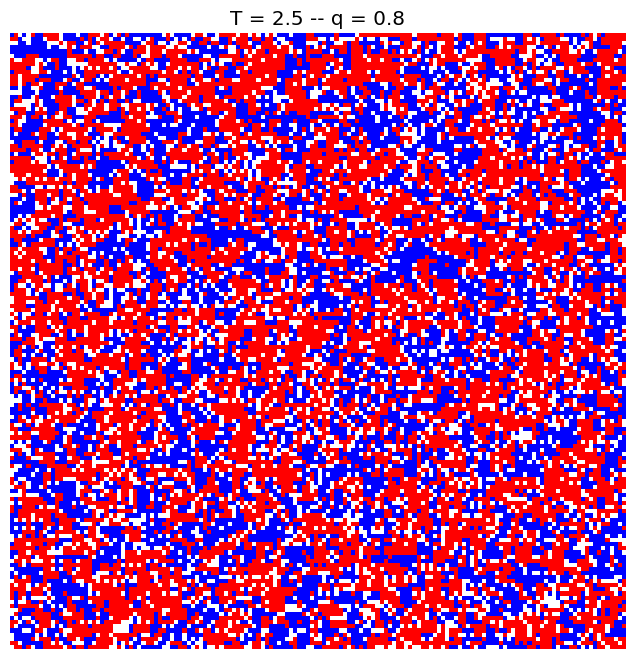

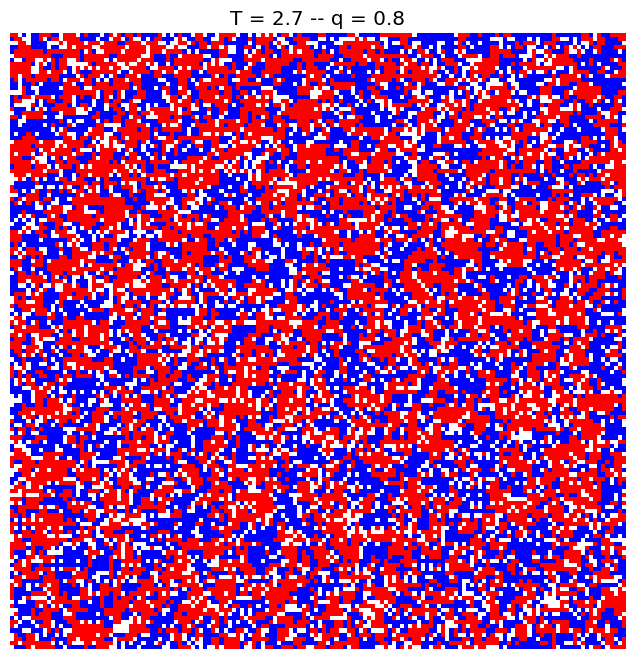

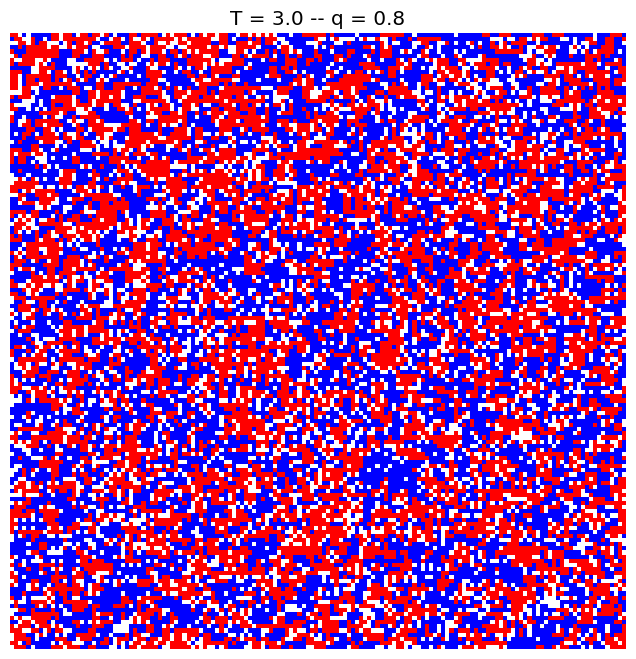

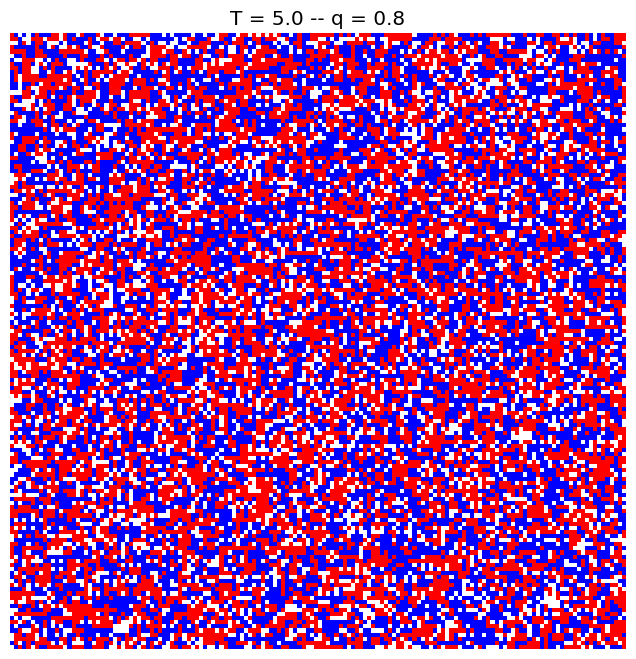



q = 0.5


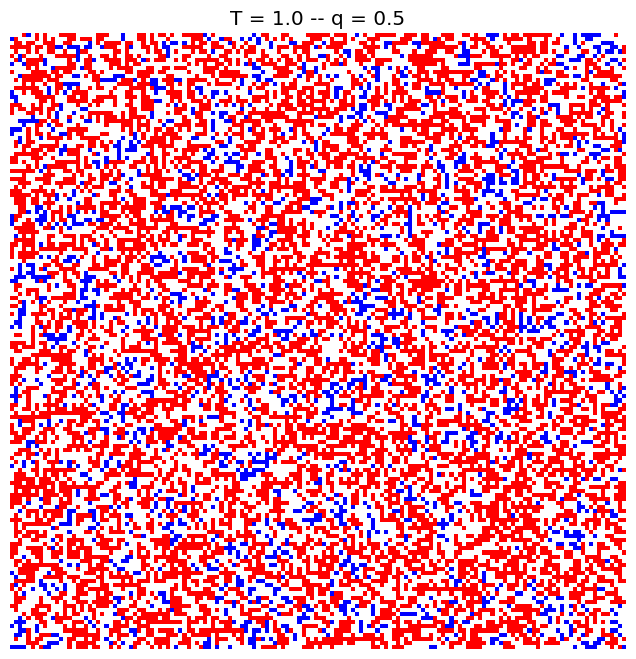

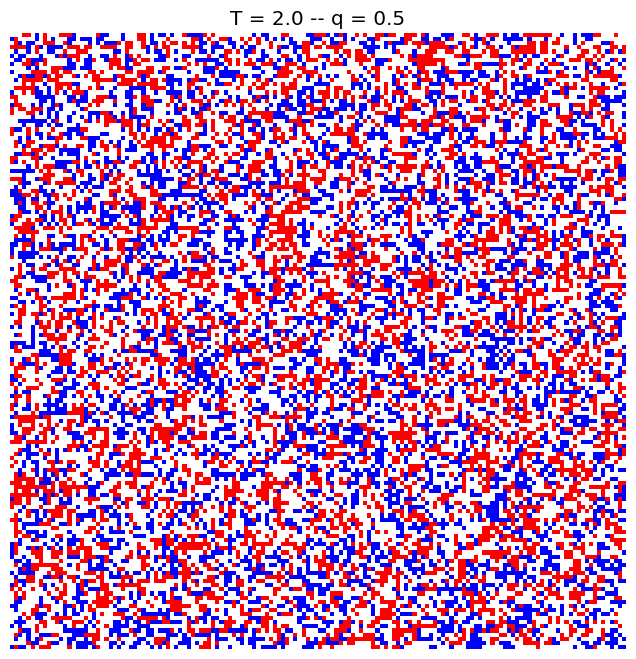

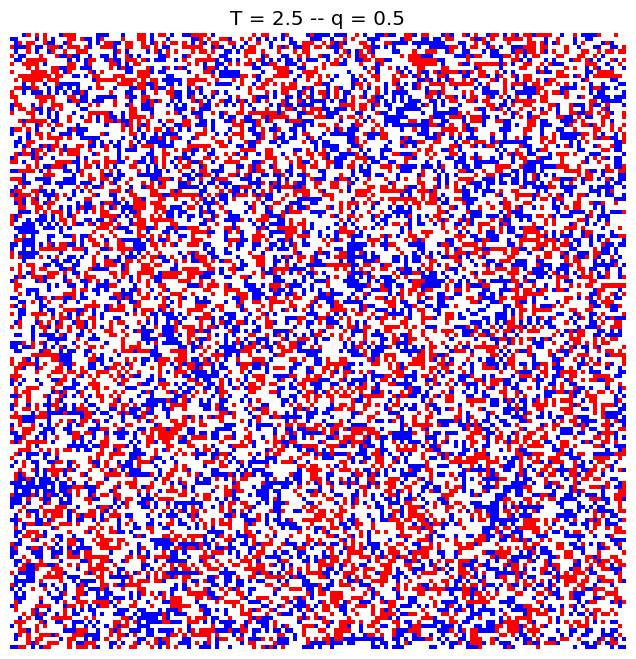

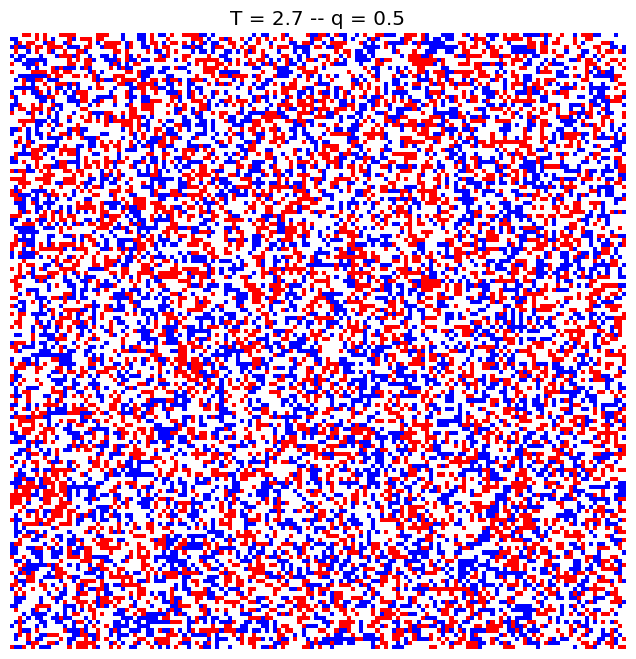

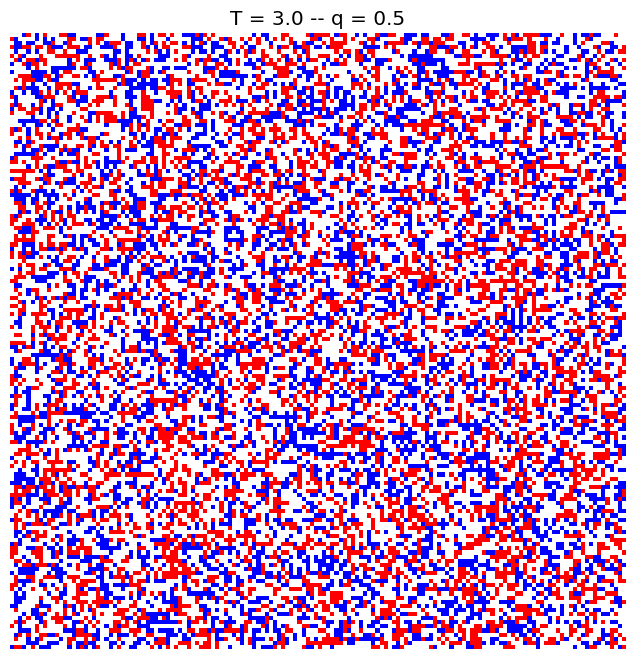

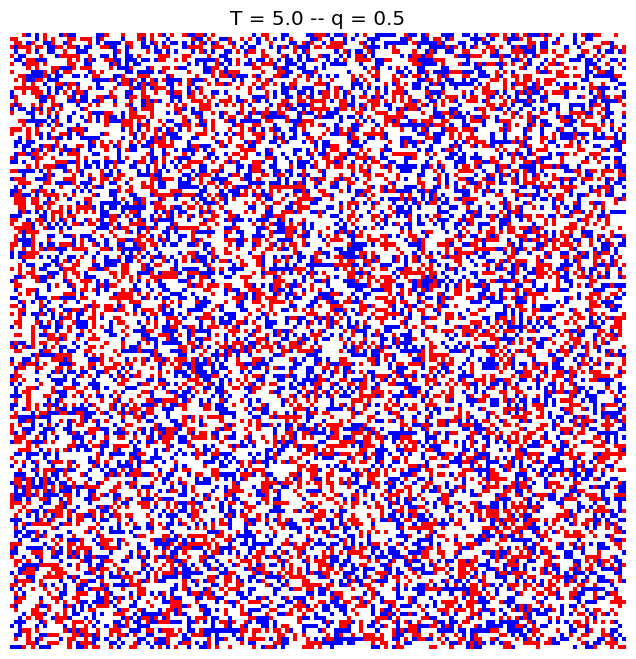

In [22]:
T_vals = np.linspace(0.1, 5, 50)
# for q in [1, 0.5, 0.2]:
N = 150
print('q = 1')
m_vals1 = transicion_fase(N=N, H=0, T_vals=T_vals, q=1.0)
print('\n\nq = 0.8')
m_vals2 = transicion_fase(N=N, H=0, T_vals=T_vals, q=0.8)
print('\n\nq = 0.5')
m_vals3 = transicion_fase(N=N, H=0, T_vals=T_vals, q=0.5)


Text(0, 0.5, 'm')

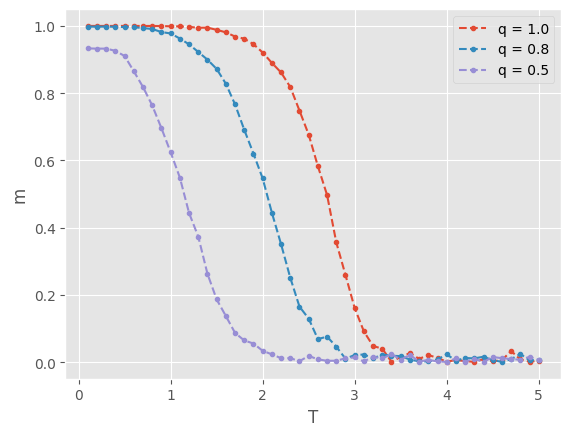

In [23]:
plt.plot(T_vals,m_vals1,'--.',label=f'q = {1.0}')
plt.plot(T_vals,m_vals2,'--.',label=f'q = {0.8}')
plt.plot(T_vals,m_vals3,'--.',label=f'q = {0.5}')
plt.legend()
plt.xlabel('T')
plt.ylabel('m')
#plt.title('Transición de fase')